# O filme é um blockbuster?
### Árvores de decisão para prever o sucesso de bilheteria antes da estreia

**Universidade Federal de Pernambuco · Centro de Informática (CIn)**  
Estatística e Probabilidade para Computação · 2026.2 · Projeto 2 · **Grupo 6**

| Integrante | Login |
|---|---|
| Arthur Sean Cerqueira Campos | ascc2 |
| Isabela Possídio Amorim | ipa |
| João Guilherme Lemos Duarte | jgldo |
| Luis Miguel | lmfs3 |
| Mirella Fontinelle | mlfm |
| Severino João da Cruz Júnior | sjcj2 |

---

**Sumário**

1. Introdução: contextualização, objetivo e descrição dos dados
2. Análise Exploratória de Dados (EDA): limpeza, análise univariada, análise bivariada e multivariada, insights
3. Validação Estatística (Teste de Hipóteses)
4. Pré-processamento e Aplicação da Técnica
5. Resultados e Interpretação
6. Conclusão

Referências ao final do notebook.

## Configuração do ambiente

A célula abaixo carrega os pacotes usados ao longo do notebook (instalando os que faltarem) e define o padrão visual dos gráficos e algumas funções auxiliares reaproveitadas nas seções seguintes.

In [ ]:
# Pacotes da EDA. Os de modelagem (rpart, rpart.plot) são carregados na seção 4.
pacotes <- c("ggplot2", "dplyr", "tidyr", "scales")
faltando <- pacotes[!pacotes %in% rownames(installed.packages())]
if (length(faltando) > 0) install.packages(faltando, quiet = TRUE)
invisible(lapply(pacotes, function(p) suppressPackageStartupMessages(library(p, character.only = TRUE))))

set.seed(2026)   # semente única do projeto: garante que splits e validações sejam reproduzíveis
options(repr.plot.width = 10, repr.plot.height = 4.5, scipen = 999, width = 120)

# ---- Padrão visual dos gráficos ----
AZUL  <- "#2F5F9E"   # cor principal (barras e histogramas)
CINZA <- "#B5BFCC"   # categoria de contraste (ex.: não blockbuster)
TINTA <- "#1B2B48"   # linhas de referência e textos

theme_set(
  theme_minimal(base_size = 13) +
    theme(panel.grid.minor   = element_blank(),
          panel.grid.major.x = element_blank(),
          plot.title         = element_text(face = "bold", color = TINTA),
          plot.subtitle      = element_text(color = "grey35"),
          axis.title         = element_text(color = "grey30"))
)

# ---- Funções auxiliares ----
# Medidas-resumo de uma variável numérica
resumo_num <- function(x) {
  q   <- quantile(x, c(.25, .5, .75))
  iqr <- q[[3]] - q[[1]]
  data.frame(
    n          = length(x),
    media      = mean(x),
    mediana    = q[[2]],
    desvio     = sd(x),
    minimo     = min(x),
    Q1         = q[[1]],
    Q3         = q[[3]],
    maximo     = max(x),
    CV_pct     = 100 * sd(x) / mean(x),
    assimetria = mean((x - mean(x))^3) / sd(x)^3,
    outliers   = sum(x < q[[1]] - 1.5 * iqr | x > q[[3]] + 1.5 * iqr)
  )
}

# Valores em milhões de dólares (US$ 15,0 mi)
mi  <- label_number(scale = 1e-6, prefix = "US$ ", suffix = " mi",
                    big.mark = ".", decimal.mark = ",", accuracy = 0.1)
mi0 <- label_number(scale = 1e-6, prefix = "US$ ", suffix = " mi",
                    big.mark = ".", decimal.mark = ",", accuracy = 1)

# Números no padrão brasileiro: 4.327 e 86,54%
br <- function(x, d = 0) formatC(x, format = "f", digits = d, big.mark = ".", decimal.mark = ",")

# 1. Introdução

## 1.1 Contextualização

A indústria cinematográfica envolve investimentos altos e retorno incerto: um mesmo orçamento e um mesmo estilo de filme podem resultar em um fracasso financeiro ou em um sucesso gigante de bilheteria. Para um estúdio, a decisão de quanto investir em um projeto é tomada **antes da estreia**, com informação incompleta. Identificar antecipadamente quais características estão associadas ao sucesso ajuda a decidir onde vale a pena arriscar.

No Projeto 1, propusemos atacar esse problema com **árvores de decisão**, inspirados no estudo de Afonso et al. (2012), que usou uma árvore CART enxuta (apenas duas variáveis) para classificar o risco de influenza em pacientes, com AUROC de 0,76 na validação. As árvores foram escolhidas porque:

- geram regras do tipo *se… então…* fáceis de explicar para quem toma a decisão de negócio;
- aceitam variáveis numéricas e categóricas sem normalização;
- capturam interações entre as variáveis.

Para isso, usamos o dataset **"What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue"**, que simula o cenário de um estúdio que precisa decidir quanto investir antes de saber se o filme vai render.

## 1.2 Objetivo

**Pergunta:** usando apenas atributos **conhecidos antes do lançamento** (década, gênero, duração e orçamento), uma árvore de decisão consegue distinguir os filmes *blockbusters* dos demais?

**Objetivo:** construir e interpretar uma árvore de decisão de classificação para a variável-alvo `blockbuster` e avaliá-la em dados que ela não viu durante o treino. No dataset, um filme é **blockbuster** (`blockbuster = 1`) quando:

> **receita > 3 × orçamento** &nbsp;e&nbsp; **receita > US\$ 100 milhões**

**Hipóteses definidas no Projeto 1:**

- **H0:** a árvore **não supera** o *baseline* que sempre prevê a classe majoritária.
- **H1:** a árvore **supera** o *baseline* em F1 da classe blockbuster no conjunto de teste.

**Critério de sucesso:** F1 acima do *baseline* e uma árvore legível, com profundidade menor que 4. A expectativa inicial era que **orçamento e gênero** aparecessem nas primeiras divisões.

**Variáveis que ficam de fora do modelo principal:**

- `revenue_usd`, `profit_usd` e `roi` derivam diretamente da receita, que define o alvo. Usá-las seria **vazamento de informação** (*data leakage*): o modelo "veria a resposta".
- `rating`, `vote_count` e `popularity` só são conhecidas **depois do lançamento**, quando a decisão de investimento já foi tomada.

Essas variáveis aparecem apenas nos **experimentos de controle** (seção 4), para mostrar o efeito do vazamento e o ganho que os sinais do público trariam.

## 1.3 Descrição dos dados

- **Fonte:** Kaggle, *"What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue"*, de V. R. Leelavathi, licença CC0 (domínio público).
- **Tamanho:** 5.000 filmes lançados entre 1980 e 2024, com 14 colunas.
- **Natureza:** o dataset é **sintético**, ou seja, gerado por simulação (os títulos vão de `Movie_0001` a `Movie_5000`). Por isso, as conclusões valem para o **método**, não para a indústria real.

**Dicionário de dados**

| Variável | Tipo | Descrição | Papel na análise |
|---|---|---|---|
| `movie_id` | inteiro | Identificador único do filme | Identificador |
| `title` | texto | Título sintético (`Movie_0001` a `Movie_5000`) | Identificador |
| `year` | inteiro | Ano de lançamento (1980 a 2024) | Informativa (redundante com `decade`) |
| `decade` | categórica | Década de lançamento (1980s a 2020s) | **Preditora** |
| `genre` | categórica | Gênero principal (10 categorias) | **Preditora** |
| `runtime_min` | inteiro | Duração em minutos (60 a 185) | **Preditora** |
| `budget_usd` | numérica | Orçamento de produção, em US\$ | **Preditora** |
| `revenue_usd` | numérica | Receita de bilheteria, em US\$ | Excluída (vazamento) |
| `profit_usd` | numérica | Lucro = receita − orçamento | Excluída (vazamento) |
| `roi` | numérica | Retorno = lucro / orçamento | Excluída (vazamento) |
| `rating` | numérica | Nota média do público (1,0 a 10,0) | Excluída (pós-lançamento) |
| `vote_count` | inteiro | Número de votos | Excluída (pós-lançamento) |
| `popularity` | numérica | Índice de popularidade | Excluída (pós-lançamento) |
| `blockbuster` | binária | 1 = blockbuster; 0 = não blockbuster | **Alvo** |

Gêneros: Action, Adventure, Animation, Comedy, Documentary, Drama, Horror, Romance, Sci-Fi e Thriller.

`year` e `decade` carregam a mesma informação. Seguindo o plano do Projeto 1, o modelo usa a **década**; o ano é usado apenas na análise exploratória.

# 2. Análise Exploratória de Dados (EDA)

## 2.1 Carregamento e Limpeza dos Dados

### Carregamento

O arquivo `movie_blockbusters.csv` é lido da pasta do notebook. Se ele não estiver lá (por exemplo, no Google Colab), é lido diretamente do repositório do grupo no GitHub.

In [ ]:
arquivo <- "movie_blockbusters.csv"
url     <- "https://raw.githubusercontent.com/arthursean/decision-tree-blockbuster/main/movie_blockbusters.csv"

df <- read.csv(if (file.exists(arquivo)) arquivo else url, stringsAsFactors = FALSE)

dim(df)
head(df)

[1] 5000   14

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
,<int>,<chr>,<int>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>
1,1,Movie_0001,2020,2020s,Comedy,96,20892329,27392091.7,6499763.1,0.311,7.0,216326,9.64,0
2,2,Movie_0002,1981,1980s,Sci-Fi,128,306333628,1237478549.0,931144920.9,3.040,5.3,49703,7.65,1
3,3,Movie_0003,1995,1990s,Horror,79,8793950,4667245.8,-4126704.3,-0.469,3.4,9476,16.68,0
4,4,Movie_0004,1988,1980s,Comedy,101,3871710,1612737.4,-2258972.1,-0.583,8.2,15698,2.93,0
5,5,Movie_0005,2023,2020s,Documentary,75,1283539,574346.9,-709191.7,-0.553,4.3,38698,9.10,0
6,6,Movie_0006,1985,1980s,Adventure,137,17573805,213596355.1,196022550.4,11.154,6.0,4507,3.59,1


A base tem **5.000 linhas** (um filme por linha) e **14 colunas**, como descrito no dicionário de dados.

### Estrutura e tipos das variáveis

In [ ]:
str(df)

'data.frame':	5000 obs. of  14 variables:
 $ movie_id   : int  1 2 3 4 5 6 7 8 9 10 ...
 $ title      : chr  "Movie_0001" "Movie_0002" "Movie_0003" "Movie_0004" ...
 $ year       : int  2020 1981 1995 1988 2023 1985 2007 1981 1993 2012 ...
 $ decade     : chr  "2020s" "1980s" "1990s" "1980s" ...
 $ genre      : chr  "Comedy" "Sci-Fi" "Horror" "Comedy" ...
 $ runtime_min: int  96 128 79 101 75 137 141 93 84 129 ...
 $ budget_usd : num  20892329 306333628 8793950 3871710 1283539 ...
 $ revenue_usd: num  27392092 1237478549 4667246 1612737 574347 ...
 $ profit_usd : num  6499763 931144921 -4126704 -2258972 -709192 ...
 $ roi        : num  0.311 3.04 -0.469 -0.583 -0.553 ...
 $ rating     : num  7 5.3 3.4 8.2 4.3 6 4 3.8 6.5 4.7 ...
 $ vote_count : int  216326 49703 9476 15698 38698 4507 29592 7481 12361 13851 ...
 $ popularity : num  9.64 7.65 16.68 2.93 9.1 ...
 $ blockbuster: int  0 1 0 0 0 1 0 0 0 1 ...


O `str()` mostra **3 colunas de texto** (`title`, `decade` e `genre`), **5 colunas inteiras** (`movie_id`, `year`, `runtime_min`, `vote_count` e `blockbuster`) e **6 numéricas contínuas** (`budget_usd`, `revenue_usd`, `profit_usd`, `roi`, `rating` e `popularity`). Todos os tipos foram lidos corretamente. Só `decade` e `genre` precisarão ser convertidas para fator (variável categórica), o que é feito no fim desta seção.

### Resumo estatístico

In [ ]:
summary(df)

    movie_id          title           year            decade           genre       runtime_min      budget_usd        
 Min.   :   1   Length   :5000   Min.   :1980   Length   :5000   Length   :5000   Min.   : 60.0   Min.   :    105490  
 1st Qu.:1251   N.unique :5000   1st Qu.:1991   N.unique :   5   N.unique :  10   1st Qu.: 93.0   1st Qu.:   5072756  
 Median :2500   N.blank  :   0   Median :2002   N.blank  :   0   N.blank  :   0   Median :109.0   Median :  15013509  
 Mean   :2500   Min.nchar:  10   Mean   :2002   Min.nchar:   5   Min.nchar:   5   Mean   :109.4   Mean   :  43207644  
 3rd Qu.:3750   Max.nchar:  10   3rd Qu.:2013   Max.nchar:   5   Max.nchar:  11   3rd Qu.:126.0   3rd Qu.:  41918082  
 Max.   :5000                    Max.   :2024                                     Max.   :185.0   Max.   :2369800987  
  revenue_usd            profit_usd               roi              rating         vote_count         popularity    
 Min.   :      14032   Min.   : -800900200   Min.  

O `summary()` já antecipa as principais características da base:

- **Orçamento, receita, votos e popularidade** têm a média muito acima da mediana (por exemplo, orçamento com mediana de US\$ 15,0 mi e média de US\$ 43,2 mi), o que indica **forte assimetria à direita**. Os máximos também são extremos (orçamento de US\$ 2,37 bi e receita de US\$ 14,96 bi). Essas distribuições são analisadas na seção 2.2.
- **Duração** (60 a 185 min, média de 109,4) e **nota** (1 a 10, média de 6,0) têm média e mediana praticamente iguais, sinal de distribuições simétricas.
- O **ROI** vai de −0,98 (o filme perdeu 98% do orçamento) a 43,3 (rendeu 43 vezes o orçamento).
- A média de `blockbuster` é **0,1346**: só 13,46% dos filmes são blockbusters (seção 2.2.1).

### Valores faltantes

In [ ]:
colSums(is.na(df))

# Strings vazias nas colunas de texto
sapply(df[sapply(df, is.character)], function(x) sum(trimws(x) == ""))

movie_id       title        year      decade       genre runtime_min  budget_usd revenue_usd  profit_usd         roi 
          0           0           0           0           0           0           0           0           0           0 
     rating  vote_count  popularity blockbuster 
          0           0           0           0

title decade  genre 
     0      0      0

**Nenhuma coluna tem valores faltantes** (`NA`) nem textos vazios. Não foi preciso remover linhas nem imputar valores.

### Duplicados

In [ ]:
c(linhas_duplicadas   = sum(duplicated(df)),
  movie_id_repetidos  = sum(duplicated(df$movie_id)),
  titulos_repetidos   = sum(duplicated(df$title)))

linhas_duplicadas movie_id_repetidos  titulos_repetidos 
                 0                  0                  0

**Não há duplicados**: nenhuma linha inteira repetida, nenhum `movie_id` repetido e nenhum título repetido.

### Consistência dos dados

Além de faltantes e duplicados, verificamos se os valores fazem sentido (estão dentro dos limites esperados) e se as colunas calculadas a partir de outras batem entre si. Cada regra abaixo conta quantos filmes a **violam**.

In [ ]:
checagens <- data.frame(
  regra = c(
    "Ano fora de 1980 a 2024",
    "Nota fora de 0 a 10",
    "Orçamento <= 0",
    "Receita <= 0",
    "Duração <= 0",
    "Votos ou popularidade negativos",
    "Década não corresponde ao ano",
    "Lucro diferente de receita - orçamento",
    "ROI diferente de lucro / orçamento",
    "Alvo diferente da definição (receita > 3x orçamento e > US$ 100 mi)"
  ),
  violacoes = c(
    sum(df$year < 1980 | df$year > 2024),
    sum(df$rating < 0 | df$rating > 10),
    sum(df$budget_usd <= 0),
    sum(df$revenue_usd <= 0),
    sum(df$runtime_min <= 0),
    sum(df$vote_count < 0 | df$popularity < 0),
    sum(paste0(floor(df$year / 10) * 10, "s") != df$decade),
    sum(abs(df$revenue_usd - df$budget_usd - df$profit_usd) > 1),               # tolerância de US$ 1 (arredondamento)
    sum(abs(round(df$profit_usd / df$budget_usd, 3) - df$roi) > 0.002),         # ROI vem com 3 casas decimais
    sum(as.integer(df$revenue_usd > 3 * df$budget_usd & df$revenue_usd > 1e8) != df$blockbuster)
  )
)
checagens

regra,violacoes
<chr>,<int>
Ano fora de 1980 a 2024,0
Nota fora de 0 a 10,0
Orçamento <= 0,0
Receita <= 0,0
Duração <= 0,0
Votos ou popularidade negativos,0
Década não corresponde ao ano,0
Lucro diferente de receita - orçamento,0
ROI diferente de lucro / orçamento,0


**Todas as 10 regras têm zero violações.** Em especial:

- a coluna `decade` corresponde exatamente ao ano de lançamento;
- `profit_usd` e `roi` foram calculados corretamente a partir da receita e do orçamento;
- a coluna `blockbuster` segue **exatamente** a definição do dataset (receita > 3× o orçamento **e** receita > US\$ 100 mi), então podemos usá-la como alvo sem recalcular.

### Ajuste de tipos

Por fim, convertemos as variáveis categóricas para fator. A década é ordenada cronologicamente. O alvo continua numérico (0/1) durante a EDA, porque isso permite calcular taxas com uma simples média; ele é convertido para fator na preparação do modelo (seção 4.1).

In [ ]:
df$decade <- factor(df$decade, levels = c("1980s", "1990s", "2000s", "2010s", "2020s"))
df$genre  <- factor(df$genre)

# Grupos de variáveis, usados nas próximas seções
vars_pre       <- c("decade", "genre", "runtime_min", "budget_usd")   # preditoras (pré-lançamento)
vars_vazamento <- c("revenue_usd", "profit_usd", "roi")              # derivadas do alvo
vars_pos       <- c("rating", "vote_count", "popularity")            # pós-lançamento
alvo           <- "blockbuster"

str(df[, c(vars_pre, alvo)])

'data.frame':	5000 obs. of  5 variables:
 $ decade     : Factor w/ 5 levels "1980s","1990s",..: 5 1 2 1 5 1 3 1 2 4 ...
 $ genre      : Factor w/ 10 levels "Action","Adventure",..: 4 9 7 4 5 2 1 4 7 2 ...
 $ runtime_min: int  96 128 79 101 75 137 141 93 84 129 ...
 $ budget_usd : num  20892329 306333628 8793950 3871710 1283539 ...
 $ blockbuster: int  0 1 0 0 0 1 0 0 0 1 ...


### Conclusão da limpeza

A base está **completa, sem duplicados e internamente consistente**, então **nenhuma linha foi removida** e as 5.000 observações seguem para a análise. Os pontos de atenção, tratados nas próximas seções, são:

- **dados sintéticos:** as conclusões valem para o método, não para o mercado real de cinema;
- **valores financeiros extremos** (orçamento e receita com cauda longa), analisados na seção 2.2;
- **desbalanceamento do alvo** (13,46% de blockbusters), que define as métricas de avaliação do modelo.

## 2.2 Análise Univariada

Nesta etapa olhamos **cada variável isoladamente**, para entender sua distribuição (formato, centro, dispersão e valores extremos) antes de cruzá-las com o alvo na seção 2.3.

Analisamos com mais detalhe as variáveis que entram no modelo principal, ou seja, as conhecidas **antes da estreia**:

| Variável | Tipo | O que olhamos |
|---|---|---|
| `blockbuster` | alvo binário | proporção das classes |
| `budget_usd` | numérica contínua | histograma, boxplot, medidas-resumo, outliers |
| `runtime_min` | numérica discreta | histograma, boxplot, medidas-resumo |
| `genre` | categórica (10 níveis) | frequências absolutas e relativas |
| `decade` / `year` | categórica / numérica | frequências por década e por ano |

No fim, fazemos uma passagem rápida pelas variáveis que **não** entram no modelo principal (receita, nota, votos e popularidade), porque elas aparecem nos experimentos de controle da seção 4.

### 2.2.1 Variável-alvo: `blockbuster`

Começamos pelo alvo, porque a proporção das classes define como o modelo será avaliado.

blockbuster,n,classe,pct
<int>,<int>,<fct>,<dbl>
0,4327,Não blockbuster,86.54
1,673,Blockbuster,13.46


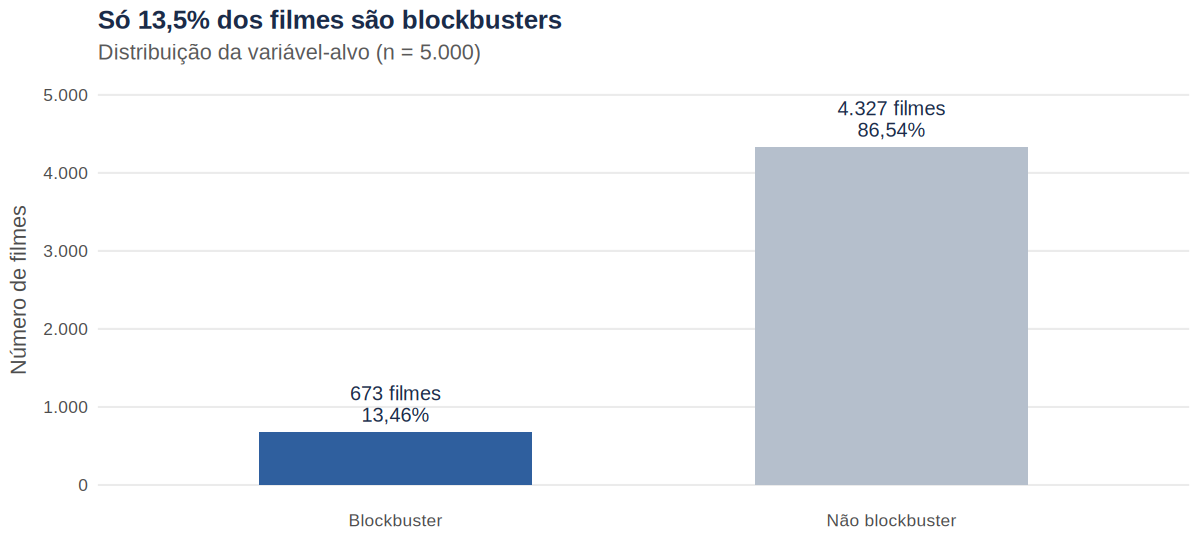

In [ ]:
classes <- df %>%
  count(blockbuster) %>%
  mutate(classe = factor(ifelse(blockbuster == 1, "Blockbuster", "Não blockbuster"),
                         levels = c("Blockbuster", "Não blockbuster")),
         pct    = 100 * n / sum(n))
classes

ggplot(classes, aes(x = classe, y = n, fill = classe)) +
  geom_col(width = 0.55) +
  geom_text(aes(label = paste0(br(n), " filmes\n", br(pct, 2), "%")),
            vjust = -0.3, color = TINTA, size = 4.2, lineheight = 0.9) +
  scale_fill_manual(values = c("Blockbuster" = AZUL, "Não blockbuster" = CINZA), guide = "none") +
  scale_y_continuous(limits = c(0, 5000), labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "Só 13,5% dos filmes são blockbusters",
       subtitle = "Distribuição da variável-alvo (n = 5.000)",
       x = NULL, y = "Número de filmes")

**Observações**

- São **673 blockbusters (13,46%)** contra **4.327 não blockbusters (86,54%)**, uma razão de cerca de **1 para 6,4**. A base é **desbalanceada**.
- Consequência direta: um "modelo" que sempre responde *não blockbuster* acerta **86,5%** dos filmes sem aprender nada, mas tem recall e F1 iguais a **zero** para a classe que nos interessa. Por isso, como planejado no Projeto 1, a **acurácia não será a métrica principal**: avaliaremos **precisão, recall e F1 da classe blockbuster** e a AUROC.
- O desbalanceamento também justifica o **split 70/30 estratificado** (seção 4), para que treino e teste mantenham a mesma proporção de blockbusters (aproximadamente 13,5%).
- Esses valores completam o painel de classes apresentado no Projeto 1, que ainda não trazia as proporções.

### 2.2.2 Orçamento: `budget_usd`

O orçamento é a principal variável numérica pré-lançamento e, pela expectativa do Projeto 1, uma das candidatas às primeiras divisões da árvore.

In [ ]:
resumo_orc <- resumo_num(df$budget_usd)
resumo_orc %>%
  mutate(across(c(media, mediana, desvio, minimo, Q1, Q3, maximo), mi),
         across(c(CV_pct, assimetria), ~ round(.x, 2)))

cat("Filmes com orçamento > US$ 100 mi:", sum(df$budget_usd > 1e8),
    paste0("(", br(100 * mean(df$budget_usd > 1e8), 1), "%)\n"))
cat("Filmes com orçamento > US$ 400 mi:", sum(df$budget_usd > 4e8), "\n")
cat("Percentis 90, 95 e 99:", mi(quantile(df$budget_usd, c(.90, .95, .99))), "\n")

n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>
5000,"US$ 43,2 mi","US$ 15,0 mi","US$ 99,0 mi","US$ 0,1 mi","US$ 5,1 mi","US$ 41,9 mi","US$ 2.369,8 mi",229.06,8.69,523


Filmes com orçamento > US$ 100 mi: 507 (10,1%)
Filmes com orçamento > US$ 400 mi: 56 
Percentis 90, 95 e 99: US$ 101,0 mi US$ 162,6 mi US$ 412,7 mi 


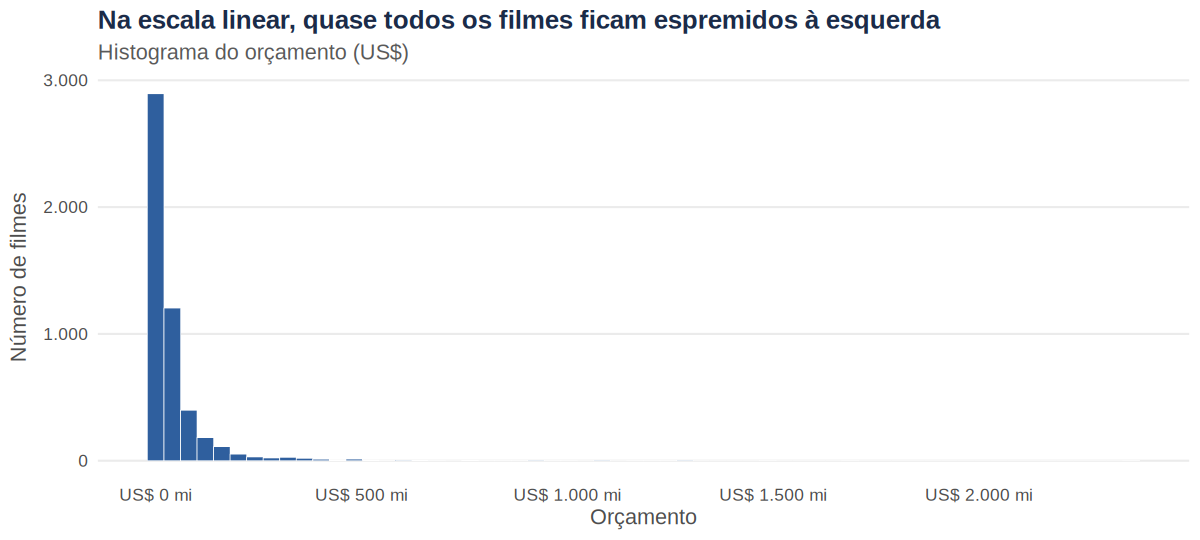

In [ ]:
# Escala linear: mostra o problema da assimetria
ggplot(df, aes(x = budget_usd)) +
  geom_histogram(bins = 60, fill = AZUL, color = "white", linewidth = 0.2) +
  scale_x_continuous(labels = mi0, breaks = seq(0, 2e9, 5e8)) +
  scale_y_continuous(labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "Na escala linear, quase todos os filmes ficam espremidos à esquerda",
       subtitle = "Histograma do orçamento (US$)",
       x = "Orçamento", y = "Número de filmes")

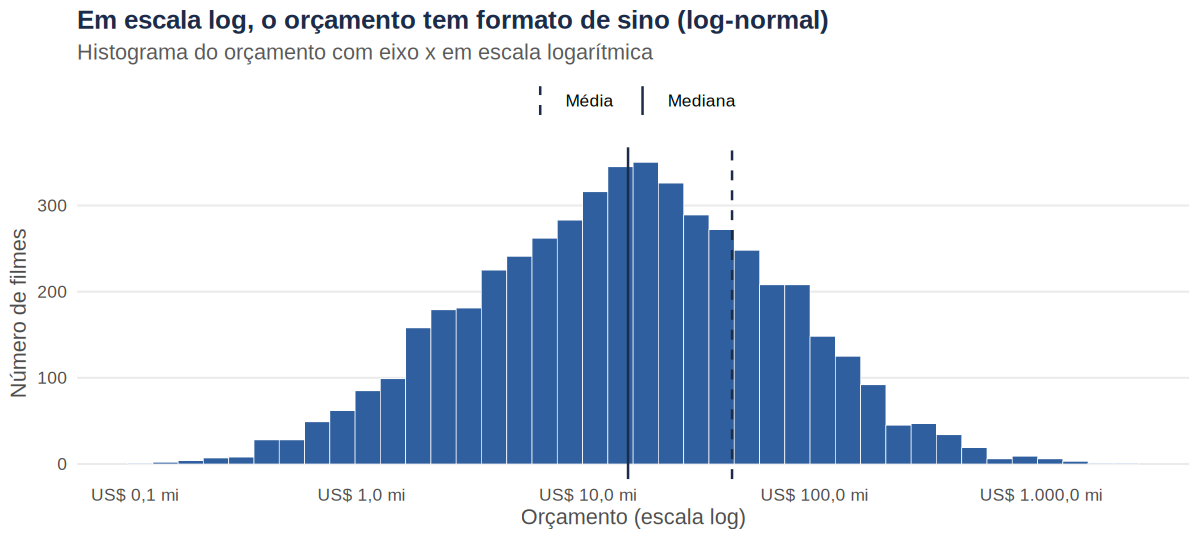

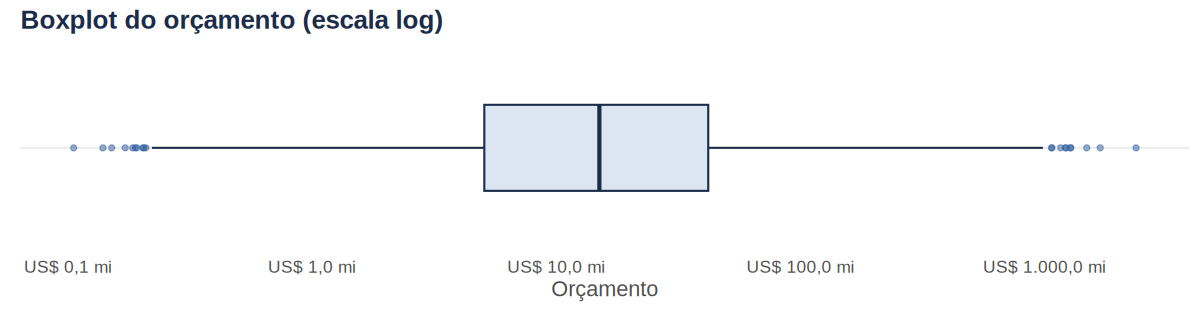

In [ ]:
# Escala logarítmica: revela o formato real da distribuição
refs <- data.frame(tipo  = c("Mediana", "Média"),
                   valor = c(median(df$budget_usd), mean(df$budget_usd)))

ggplot(df, aes(x = budget_usd)) +
  geom_histogram(bins = 40, fill = AZUL, color = "white", linewidth = 0.2) +
  geom_vline(data = refs, aes(xintercept = valor, linetype = tipo), color = TINTA, linewidth = 0.7) +
  scale_linetype_manual(values = c("Mediana" = "solid", "Média" = "dashed"), name = NULL) +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  labs(title = "Em escala log, o orçamento tem formato de sino (log-normal)",
       subtitle = "Histograma do orçamento com eixo x em escala logarítmica",
       x = "Orçamento (escala log)", y = "Número de filmes") +
  theme(legend.position = "top")

options(repr.plot.height = 2.6)
ggplot(df, aes(x = budget_usd, y = "")) +
  geom_boxplot(fill = "#DCE5F2", color = TINTA, outlier.color = AZUL,
               outlier.alpha = 0.5, outlier.size = 1.4, width = 0.5) +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  labs(title = "Boxplot do orçamento (escala log)", x = "Orçamento", y = NULL)
options(repr.plot.height = 4.5)

**Observações**

- **Forte assimetria à direita.** A média (**US\$ 43,2 mi**) é quase **3 vezes** a mediana (**US\$ 15,0 mi**), e o coeficiente de assimetria é **8,7**. Metade dos filmes custa entre **US\$ 5,1 mi e US\$ 41,9 mi** (Q1 e Q3), mas a cauda vai até **US\$ 2,37 bi**.
- **Distribuição log-normal.** Em escala logarítmica o histograma vira um sino quase simétrico (assimetria do log ≈ **−0,06**), o que é coerente com a forma como o dataset sintético foi gerado.
- **Outliers.** Pelo critério de 1,5 × IIQ, **523 filmes (10,5%)** são outliers, todos no lado alto. Há **56 filmes acima de US\$ 400 mi** e o máximo (US\$ 2,37 bi) é bem maior que qualquer orçamento real de Hollywood, o que reforça que os dados são sintéticos.
- **Decisão: manter os outliers e não transformar a variável para o modelo.** A árvore escolhe pontos de corte ("orçamento > X?"), então só a **ordem** dos valores importa: aplicar log não muda as divisões possíveis, e os valores extremos não "puxam" o modelo como fariam numa regressão. O log é usado aqui **só para visualizar**.
- Cerca de **10% dos filmes** custam mais de US\$ 100 mi. Como a definição de blockbuster exige receita acima de US\$ 100 mi **e** de 3× o orçamento, espera-se que a relação entre orçamento e blockbuster seja forte, o que será verificado na seção 2.3.

### 2.2.3 Duração: `runtime_min`

In [ ]:
resumo_num(df$runtime_min) %>% mutate(across(where(is.numeric), ~ round(.x, 2)))

table(cut(df$runtime_min, breaks = c(59, 90, 120, 150, 185),
          labels = c("60–90 min", "91–120 min", "121–150 min", "151–185 min")))

n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5000,109.36,109,22.22,60,93,126,185,20.32,0.07,2



  60–90 min  91–120 min 121–150 min 151–185 min 
       1060        2327        1467         146 

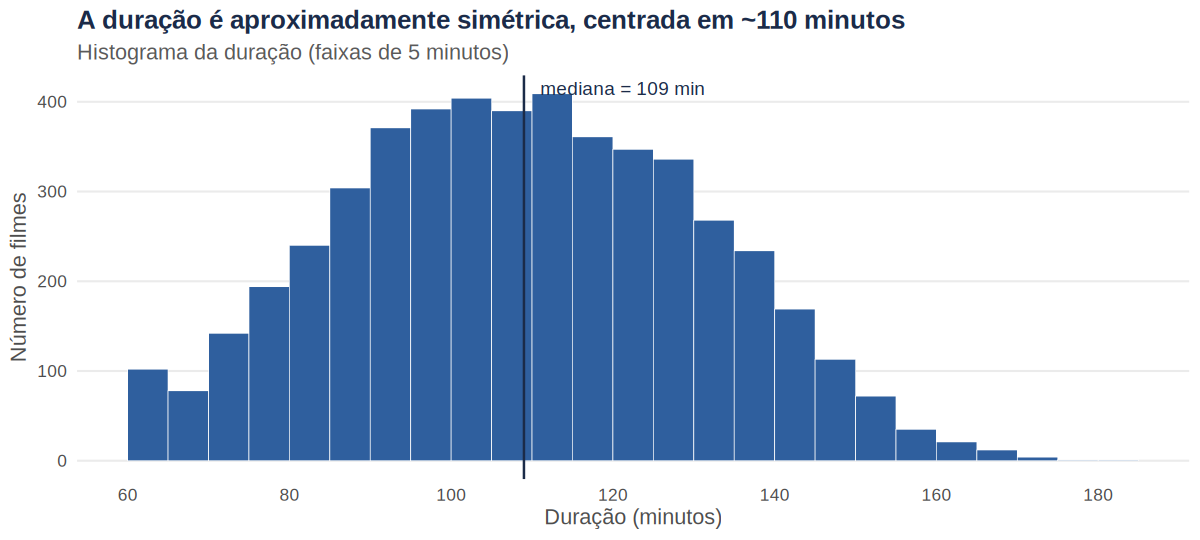

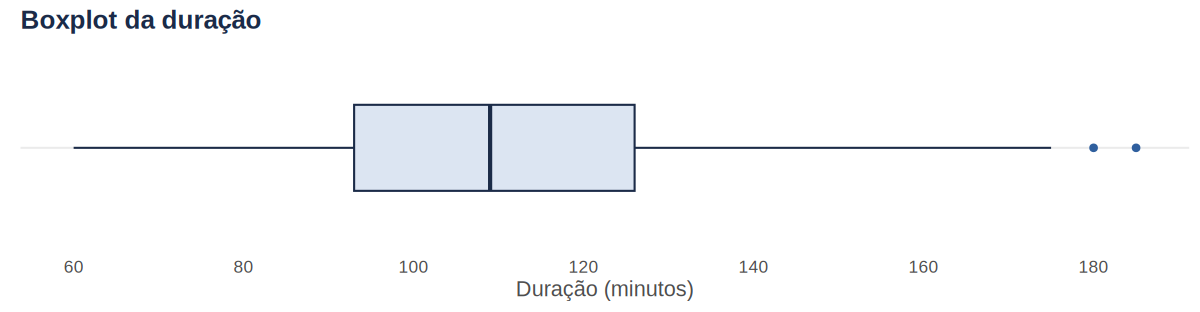

In [ ]:
ggplot(df, aes(x = runtime_min)) +
  geom_histogram(binwidth = 5, boundary = 60, fill = AZUL, color = "white", linewidth = 0.2) +
  geom_vline(xintercept = median(df$runtime_min), color = TINTA, linewidth = 0.7) +
  annotate("text", x = median(df$runtime_min) + 2, y = Inf, vjust = 1.5, hjust = 0,
           label = paste0("mediana = ", median(df$runtime_min), " min"), color = TINTA, size = 4) +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "A duração é aproximadamente simétrica, centrada em ~110 minutos",
       subtitle = "Histograma da duração (faixas de 5 minutos)",
       x = "Duração (minutos)", y = "Número de filmes")

options(repr.plot.height = 2.6)
ggplot(df, aes(x = runtime_min, y = "")) +
  geom_boxplot(fill = "#DCE5F2", color = TINTA, outlier.color = AZUL, width = 0.5) +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "Boxplot da duração", x = "Duração (minutos)", y = NULL)
options(repr.plot.height = 4.5)

**Observações**

- A duração vai de **60 a 185 minutos**, com média (**109,4 min**) praticamente igual à mediana (**109 min**) e assimetria perto de zero (**0,07**): uma distribuição **aproximadamente simétrica**, sem a cauda longa do orçamento.
- O desvio padrão é de **22,2 min**, e metade dos filmes dura entre **93 e 126 minutos**.
- Só **2 outliers** pelo critério do IIQ, ambos no limite superior. Não há durações impossíveis (nenhum valor ≤ 0).
- A primeira barra (60–64 min) é mais alta que a seguinte porque **47 filmes têm exatamente 60 minutos**: o gerador do dataset parece ter "cortado" as durações menores em 60. É um artefato da simulação, não um padrão real, e afeta menos de 1% da base.
- Embora o formato seja de sino, o teste de Shapiro-Wilk rejeita a normalidade (p < 0,001). Com n = 5.000, o teste detecta desvios muito pequenos; isso é relevante para a seção 3, onde testes não paramétricos podem ser mais adequados.
- Não é preciso tratar nada nesta variável para a árvore.

### 2.2.4 Gênero: `genre`

genre,n,pct
<fct>,<int>,<dbl>
Documentary,544,10.88
Animation,522,10.44
Adventure,515,10.30
Drama,507,10.14
Comedy,499,9.98
Thriller,499,9.98
Action,488,9.76
Sci-Fi,478,9.56
Horror,477,9.54


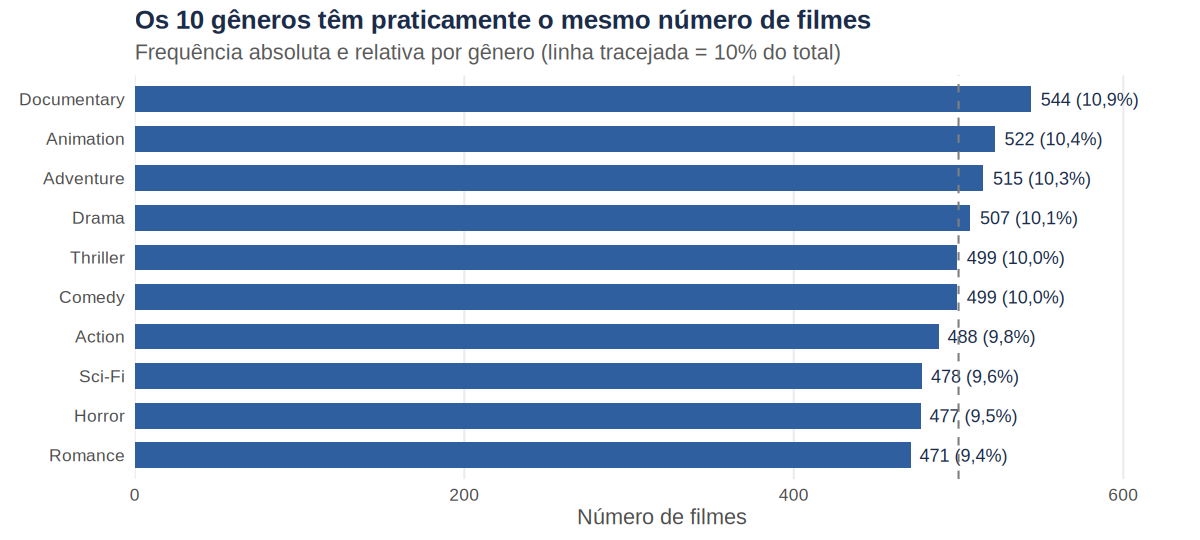

In [ ]:
generos <- df %>%
  count(genre, sort = TRUE) %>%
  mutate(pct = 100 * n / sum(n))
generos

ggplot(generos, aes(x = n, y = reorder(genre, n))) +
  geom_col(fill = AZUL, width = 0.65) +
  geom_text(aes(label = paste0(br(n), " (", br(pct, 1), "%)")), hjust = -0.1, color = TINTA, size = 3.8) +
  geom_vline(xintercept = nrow(df) / 10, linetype = "dashed", color = "grey50") +
  scale_x_continuous(limits = c(0, 640), expand = c(0, 0)) +
  labs(title = "Os 10 gêneros têm praticamente o mesmo número de filmes",
       subtitle = "Frequência absoluta e relativa por gênero (linha tracejada = 10% do total)",
       x = "Número de filmes", y = NULL) +
  theme(panel.grid.major.y = element_blank(), panel.grid.major.x = element_line())

**Observações**

- Há **10 gêneros**, e cada um tem entre **471 (Romance, 9,4%)** e **544 filmes (Documentary, 10,9%)**: a distribuição é **praticamente uniforme**, em torno de 10% cada.
- Isso é bom para a modelagem: **nenhuma categoria é rara**, então a árvore tem amostras suficientes em cada gênero e não há necessidade de agrupar categorias em "Outros".
- Também significa que qualquer diferença na **taxa de blockbuster** entre os gêneros (analisada na seção 2.3) não vem de um gênero ter muito mais filmes que outro.

### 2.2.5 Década e ano: `decade` e `year`

decade,n,pct,anos_cobertos,filmes_por_ano
<fct>,<int>,<dbl>,<dbl>,<dbl>
1980s,1106,22.12,10,110.6
1990s,1081,21.62,10,108.1
2000s,1148,22.96,10,114.8
2010s,1079,21.58,10,107.9
2020s,586,11.72,5,117.2


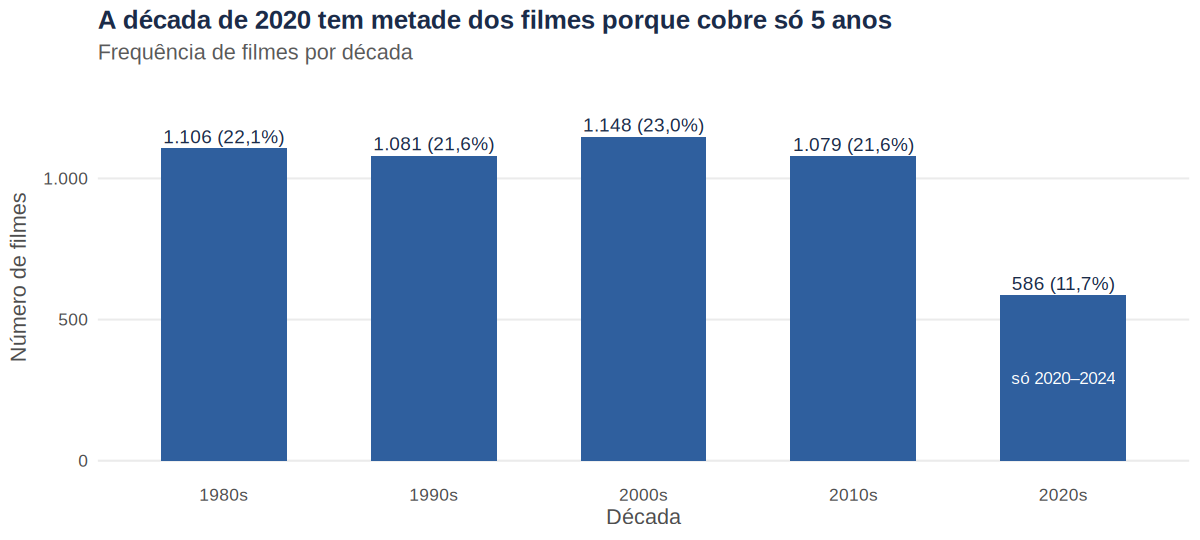

In [ ]:
decadas <- df %>%
  count(decade) %>%
  mutate(pct = 100 * n / sum(n),
         anos_cobertos = c(10, 10, 10, 10, 5),
         filmes_por_ano = n / anos_cobertos)
decadas

ggplot(decadas, aes(x = decade, y = n)) +
  geom_col(fill = AZUL, width = 0.6) +
  geom_text(aes(label = paste0(br(n), " (", br(pct, 1), "%)")), vjust = -0.4, color = TINTA, size = 4) +
  annotate("text", x = 5, y = 586 / 2, label = "só 2020–2024", color = "white", size = 3.6) +
  scale_y_continuous(limits = c(0, 1300), labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "A década de 2020 tem metade dos filmes porque cobre só 5 anos",
       subtitle = "Frequência de filmes por década",
       x = "Década", y = "Número de filmes")

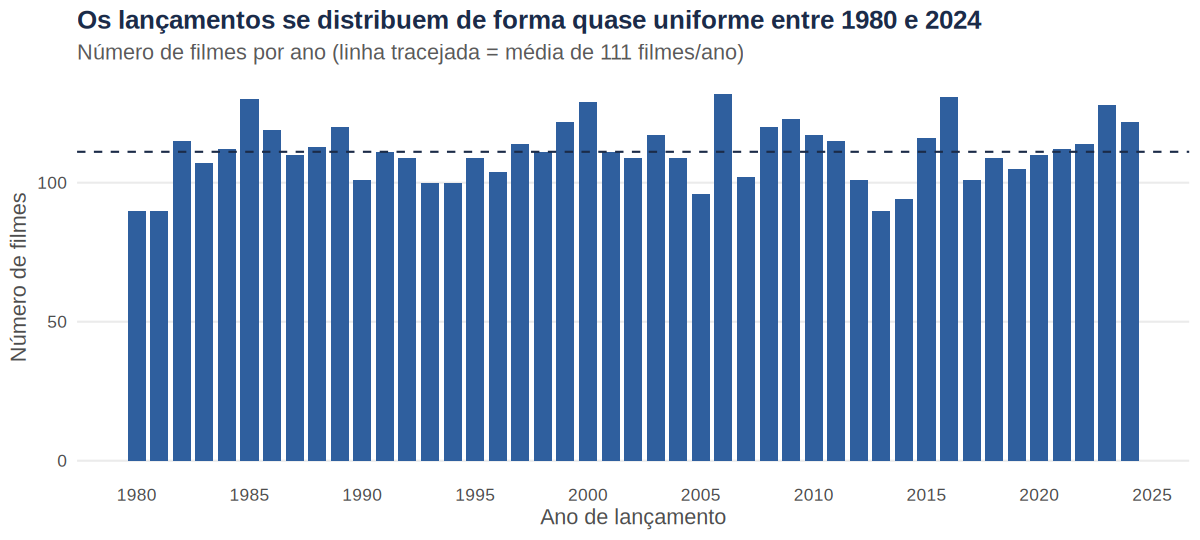

In [ ]:
ggplot(df, aes(x = year)) +
  geom_bar(fill = AZUL, width = 0.8) +
  geom_hline(yintercept = mean(table(df$year)), linetype = "dashed", color = TINTA) +
  scale_x_continuous(breaks = seq(1980, 2025, 5)) +
  labs(title = "Os lançamentos se distribuem de forma quase uniforme entre 1980 e 2024",
       subtitle = sprintf("Número de filmes por ano (linha tracejada = média de %.0f filmes/ano)", mean(table(df$year))),
       x = "Ano de lançamento", y = "Número de filmes")

**Observações**

- As quatro décadas completas têm entre **1.079 e 1.148 filmes** (cerca de 22% cada). A década de **2020 tem só 586 (11,7%)**, mas isso não é falta de dados: ela cobre apenas **2020 a 2024**. Por ano, o ritmo é o mesmo das outras décadas (cerca de 110 filmes/ano).
- Por ano, a contagem varia entre **90 e 132 filmes**, em torno da média de **111**, sem tendência clara de crescimento: o dataset **não simula** o aumento real do número de lançamentos ao longo do tempo.
- Para o modelo, usaremos a **década** como variável categórica, como no plano do Projeto 1. `year` e `decade` carregam a mesma informação, então não faz sentido usar as duas.
- A década de 2020 tem menos filmes, mas ainda são 586, o suficiente para a árvore estimar a taxa de blockbuster nesse grupo.

### 2.2.6 Variáveis fora do modelo principal

Receita, nota, votos e popularidade **não** entram no modelo principal: a receita define o alvo (vazamento) e as outras três só são conhecidas depois da estreia. Ainda assim, elas aparecem nos experimentos de controle (seção 4), então vale conhecer suas distribuições.

In [ ]:
fora <- c("revenue_usd", "rating", "vote_count", "popularity")
t(sapply(df[fora], function(x) round(unlist(resumo_num(x)), 2)))

,n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
revenue_usd,5000,131184400.53,23279983.0,501258050.25,14032.44,5707046.69,88871335.98,14955184373.97,382.10,14.62,640
rating,5000,6.00,6.0,1.49,1.00,5.00,7.00,10.00,24.92,-0.05,25
vote_count,5000,69321.52,21815.5,321030.62,87.00,7866.75,57666.75,18230861.00,463.10,40.33,548
popularity,5000,20.00,12.2,26.70,0.37,6.33,23.59,627.87,133.46,6.92,393


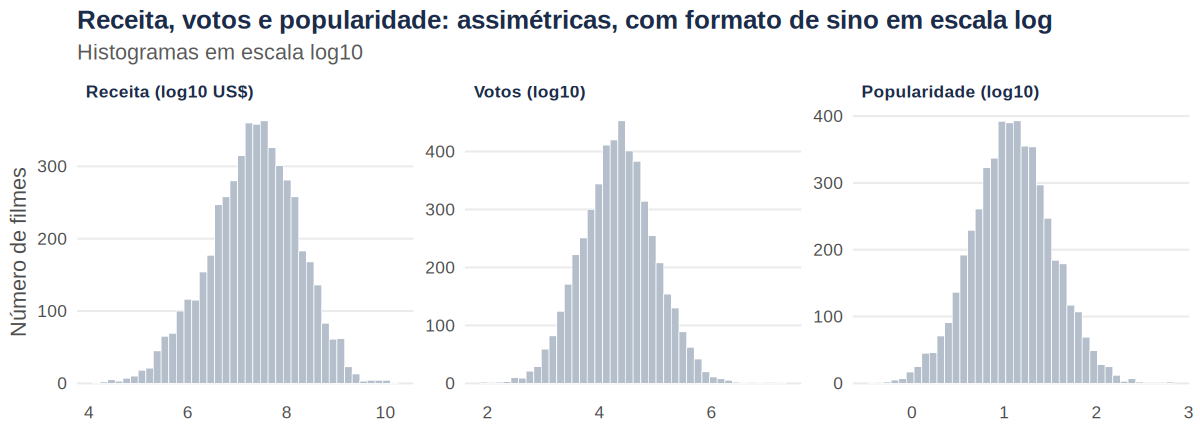

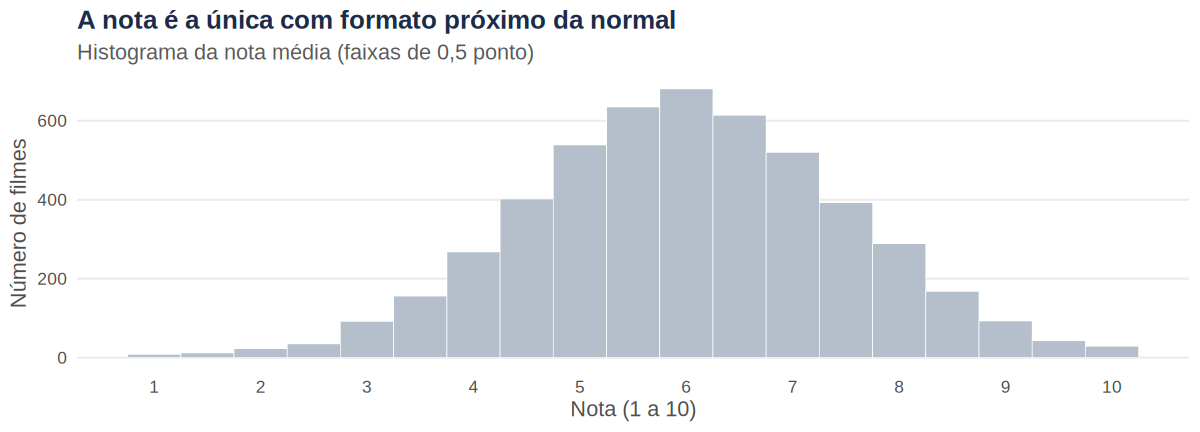

In [ ]:
log_vars <- c("revenue_usd", "vote_count", "popularity")
options(repr.plot.height = 3.6)
df %>%
  select(all_of(log_vars)) %>%
  mutate(across(everything(), log10)) %>%
  pivot_longer(everything(), names_to = "variavel", values_to = "valor") %>%
  mutate(variavel = factor(variavel, levels = log_vars,
                           labels = c("Receita (log10 US$)", "Votos (log10)", "Popularidade (log10)"))) %>%
  ggplot(aes(x = valor)) +
  geom_histogram(bins = 40, fill = CINZA, color = "white", linewidth = 0.2) +
  facet_wrap(~ variavel, scales = "free", ncol = 3) +
  labs(title = "Receita, votos e popularidade: assimétricas, com formato de sino em escala log",
       subtitle = "Histogramas em escala log10",
       x = NULL, y = "Número de filmes") +
  theme(strip.text = element_text(face = "bold", color = TINTA, hjust = 0))

# A nota tem uma casa decimal: faixas de 0,5 ponto evitam "dentes" artificiais
ggplot(df, aes(x = rating)) +
  geom_histogram(binwidth = 0.5, boundary = 0.75, fill = CINZA, color = "white", linewidth = 0.2) +
  scale_x_continuous(breaks = 1:10) +
  labs(title = "A nota é a única com formato próximo da normal",
       subtitle = "Histograma da nota média (faixas de 0,5 ponto)",
       x = "Nota (1 a 10)", y = "Número de filmes")
options(repr.plot.height = 4.5)

**Observações**

- **Receita, votos e popularidade** seguem o mesmo padrão do orçamento: **assimetria à direita muito forte** (assimetria de 14,6, 40,3 e 6,9, respectivamente) e formato de sino em escala log. A receita mediana é de **US\$ 23,3 mi**, mas a média é **US\$ 131,2 mi**.
- A **nota** é a única com formato próximo da normal: média e mediana **6,0**, desvio padrão **1,5** e 95% dos filmes entre **3,1 e 8,9**. Há um pequeno acúmulo nas pontas (5 filmes com nota 1,0 e 20 com nota 10,0), outro sinal de valores cortados nos limites da escala pela simulação.
- Ficam fora do modelo principal pelos motivos definidos no Projeto 1: a receita vaza o alvo, e nota, votos e popularidade não existem no momento da decisão de investimento.

### Resumo da análise univariada

| Variável | Formato | Destaques | Implicação para o modelo |
|---|---|---|---|
| `blockbuster` | binária | **13,46%** sim × **86,54%** não | desbalanceada: usar F1/recall/AUROC e split estratificado |
| `budget_usd` | log-normal, assimetria 8,7 | mediana US\$ 15,0 mi, média US\$ 43,2 mi; 10,5% outliers | manter sem transformação: a árvore só usa a ordem dos valores |
| `runtime_min` | aproximadamente simétrica | média 109,4 min, DP 22,2; 2 outliers | sem tratamento |
| `genre` | quase uniforme | 10 gêneros com 9,4% a 10,9% cada | sem categorias raras; sem agrupar |
| `decade` | quase uniforme por ano | 2020s com metade dos filmes por cobrir só 5 anos | usar a década como categórica |

**Pontos que passam para a seção 2.3:** como a taxa de blockbuster varia entre gêneros, décadas e faixas de orçamento, e se o orçamento continua comparável entre décadas.

## 2.3 Análise Bivariada e Multivariada

Na seção 2.2, examinamos cada variável isoladamente e levantamos duas questões centrais: como a taxa de blockbuster se comporta conforme orçamento, gênero, década e duração, e se o orçamento permanece comparável ao longo das décadas.

Nesta etapa, cruzamos as variáveis entre si e com o alvo `blockbuster` usando tabelas cruzadas, boxplots comparativos, gráfico de dispersão (*scatter*) e mapa de calor de correlações. Também incluímos as variáveis fora do modelo principal (`revenue_usd`, `profit_usd`, `roi`, `rating`, `vote_count` e `popularity`) no gráfico de dispersão e no heatmap para visualizar o vazamento de informação e antecipar o que esperar dos experimentos de controle da seção 4.

| Subseção | Cruzamento analisado | Ferramenta principal |
|---|---|---|
| 2.3.1 | `budget_usd` × `blockbuster` | Boxplot em escala log e tabela/barras por faixa |
| 2.3.2 | `genre` × `blockbuster` | Tabela cruzada e barras horizontais ordenadas |
| 2.3.3 | `decade` × `blockbuster` e `decade` × `budget_usd` | Tabela cruzada, barras e boxplot por década |
| 2.3.4 | `runtime_min` × `blockbuster` (marginal e por gênero) | Boxplots marginal e estratificado por gênero |
| 2.3.5 | `budget_usd` × `revenue_usd` × `blockbuster` | Gráfico de dispersão (*scatter*) com fronteira do alvo |
| 2.3.6 | Todas as numéricas × `blockbuster` | Mapa de calor de correlações (Spearman) |
| 2.3.7 | `genre` × `budget_usd` e `genre` × `decade` × `blockbuster` | Tabelas cruzadas e mapas de calor multivariados |

### 2.3.1 Orçamento e alvo: `budget_usd` × `blockbuster`

Pela expectativa do Projeto 1 e pelo achado da seção 2.2.2, o orçamento é o principal candidato à primeira divisão da árvore. Comparamos primeiro a distribuição do orçamento entre as duas classes e, em seguida, observamos como a taxa de blockbuster evolui por faixa de orçamento — verificando separadamente as duas condições que definem o alvo (`receita > US$ 100 mi` e `receita > 3× orçamento`).

In [ ]:
taxa_global <- mean(df$blockbuster) * 100

df_classe <- df %>%
  mutate(classe = factor(ifelse(blockbuster == 1, "Blockbuster", "Não blockbuster"),
                         levels = c("Blockbuster", "Não blockbuster")))

# Medidas-resumo do orçamento por classe
orc_por_classe <- df_classe %>%
  group_by(classe) %>%
  summarise(
    filmes  = n(),
    minimo  = mi(min(budget_usd)),
    Q1      = mi(quantile(budget_usd, 0.25)),
    mediana = mi(median(budget_usd)),
    media   = mi(mean(budget_usd)),
    Q3      = mi(quantile(budget_usd, 0.75)),
    maximo  = mi(max(budget_usd)),
    .groups = "drop"
  )
orc_por_classe

# Taxa de blockbuster por faixas de orçamento e decomposição nas duas regras do alvo
faixas_orc <- df %>%
  mutate(faixa = cut(
    budget_usd,
    breaks = c(0, 5e6, 15e6, 30e6, 50e6, 100e6, 200e6, Inf),
    labels = c("< US$ 5 mi", "US$ 5–15 mi", "US$ 15–30 mi", "US$ 30–50 mi",
               "US$ 50–100 mi", "US$ 100–200 mi", "US$ 200 mi+"),
    right = FALSE
  )) %>%
  group_by(faixa) %>%
  summarise(
    filmes        = n(),
    blockbusters  = sum(blockbuster),
    taxa_bb_pct   = round(100 * mean(blockbuster), 2),
    pct_rev_100mi = round(100 * mean(revenue_usd > 1e8), 1),
    pct_rev_3x    = round(100 * mean(revenue_usd > 3 * budget_usd), 1),
    .groups = "drop"
  )
faixas_orc

classe,filmes,minimo,Q1,mediana,media,Q3,maximo
<fct>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Blockbuster,673,"US$ 4,6 mi","US$ 31,0 mi","US$ 52,4 mi","US$ 96,5 mi","US$ 106,2 mi","US$ 2.369,8 mi"
Não blockbuster,4327,"US$ 0,1 mi","US$ 4,2 mi","US$ 11,8 mi","US$ 34,9 mi","US$ 31,1 mi","US$ 1.689,7 mi"


faixa,filmes,blockbusters,taxa_bb_pct,pct_rev_100mi,pct_rev_3x
<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>
< US$ 5 mi,1239,1,0.08,0.1,17.7
US$ 5–15 mi,1259,32,2.54,2.5,23.2
US$ 15–30 mi,872,124,14.22,14.2,26.6
US$ 30–50 mi,556,160,28.78,34.7,29.7
US$ 50–100 mi,567,175,30.86,61.4,30.9
US$ 100–200 mi,326,109,33.44,85.9,33.4
US$ 200 mi+,181,72,39.78,98.9,39.8


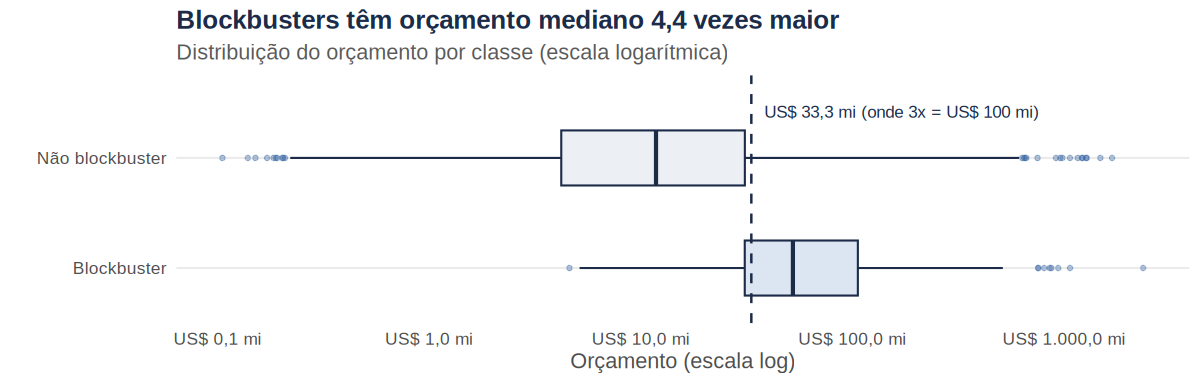

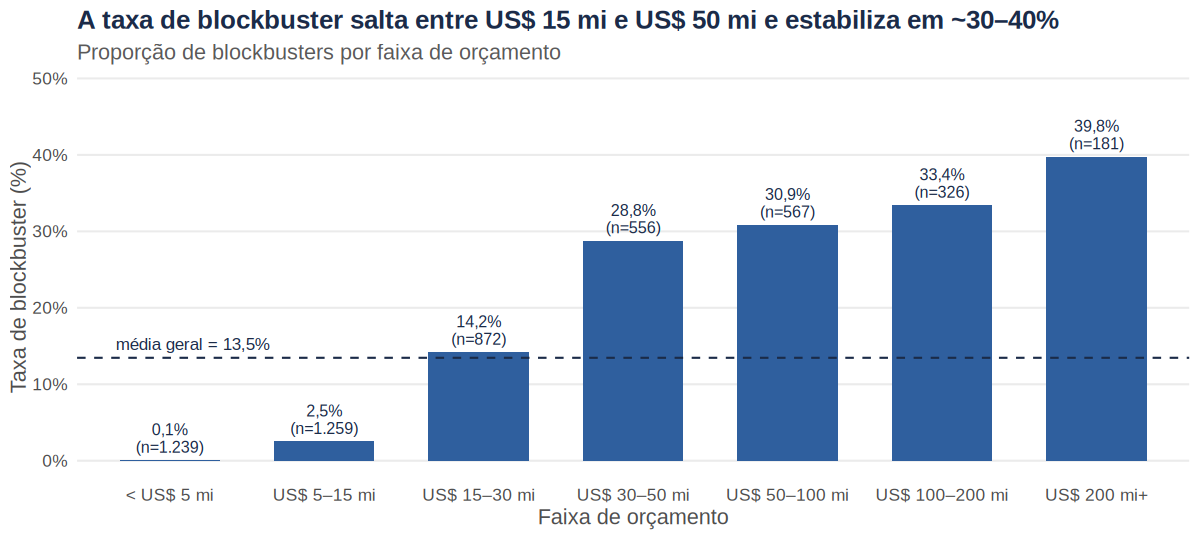

In [ ]:
options(repr.plot.height = 3.2)
ggplot(df_classe, aes(x = budget_usd, y = classe, fill = classe)) +
  geom_boxplot(color = TINTA, outlier.color = AZUL, outlier.alpha = 0.35,
               outlier.size = 1.2, width = 0.5) +
  geom_vline(xintercept = 1e8 / 3, linetype = "dashed", color = TINTA, linewidth = 0.7) +
  annotate("text", x = 1e8 / 3 * 1.15, y = 2.42, hjust = 0, color = TINTA, size = 3.6,
           label = "US$ 33,3 mi (onde 3x = US$ 100 mi)") +
  scale_fill_manual(values = c("Blockbuster" = "#DCE5F2", "Não blockbuster" = "#ECEFF4"), guide = "none") +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  scale_y_discrete(expand = expansion(add = c(0.5, 0.75))) +
  labs(title = "Blockbusters têm orçamento mediano 4,4 vezes maior",
       subtitle = "Distribuição do orçamento por classe (escala logarítmica)",
       x = "Orçamento (escala log)", y = NULL)

options(repr.plot.height = 4.5)
ggplot(faixas_orc, aes(x = faixa, y = taxa_bb_pct)) +
  geom_col(fill = AZUL, width = 0.65) +
  geom_hline(yintercept = taxa_global, linetype = "dashed", color = TINTA, linewidth = 0.6) +
  annotate("text", x = 0.65, y = taxa_global + 1.8, hjust = 0, color = TINTA, size = 3.6,
           label = paste0("média geral = ", br(taxa_global, 1), "%")) +
  geom_text(aes(label = paste0(br(taxa_bb_pct, 1), "%\n(n=", br(filmes), ")")),
            vjust = -0.25, color = TINTA, size = 3.4, lineheight = 0.9) +
  scale_y_continuous(limits = c(0, 48), labels = function(x) paste0(x, "%")) +
  labs(title = "A taxa de blockbuster salta entre US$ 15 mi e US$ 50 mi e estabiliza em ~30–40%",
       subtitle = "Proporção de blockbusters por faixa de orçamento",
       x = "Faixa de orçamento", y = "Taxa de blockbuster (%)")

**Observações**

- **Separação forte entre as classes:** o orçamento mediano dos blockbusters é de **US\$ 52,4 mi** (Q1 = US\$ 31,0 mi; Q3 = US\$ 106,2 mi), **4,4 vezes** o dos não blockbusters (**US\$ 11,8 mi**; Q1 = US\$ 4,2 mi; Q3 = US\$ 31,1 mi). Note que o primeiro quartil dos blockbusters praticamente coincide com o terceiro quartil dos não blockbusters.
- **Filtro quase perfeito na parte baixa:** abaixo de US\$ 5 mi (1.239 filmes), há apenas **1 blockbuster (0,08%)** — o menor orçamento de um blockbuster na base é **US\$ 4,6 mi**. Considerando toda a metade mais barata da base (< US\$ 15 mi, 2.498 filmes), a taxa é de apenas **1,3%** (33 blockbusters), o que significa que **95,1%** de todos os blockbusters custam US\$ 15 mi ou mais.
- **Por que a taxa dá um salto até ~US\$ 33,3 mi e depois desacelera?** A tabela de decomposição explica o mecanismo: abaixo de **US\$ 33,3 mi**, mesmo os filmes que triplicam o orçamento (17,7% a 26,6%) frequentemente não alcançam o piso de **US\$ 100 mi** de receita. Acima de US\$ 33,3 mi, qualquer filme que ultrapasse 3× o orçamento automaticamente supera US\$ 100 mi, de modo que a taxa de blockbuster passa a depender apenas do multiplicador de retorno e estabiliza entre **28,8% e 39,8%**.
- **Sinal de alerta para a árvore:** mesmo na faixa mais cara (**US\$ 200 mi+**), apenas **39,8%** dos filmes são blockbusters (abaixo de 50%). O orçamento identifica com alta precisão quem **não** será blockbuster, mas sozinho não basta para garantir a classe positiva.

### 2.3.2 Gênero e alvo: tabela cruzada `genre` × `blockbuster`

Na seção 2.2.4, vimos que os 10 gêneros têm tamanhos praticamente iguais (~500 filmes cada). A tabela cruzada abaixo mostra como os 673 blockbusters se distribuem entre eles, junto com o orçamento mediano e o retorno mediano de cada categoria.

genre,filmes,nao_bb,blockbusters,taxa_bb_pct,orc_mediano,pct_rev_3x,roi_mediano
<fct>,<int>,<int>,<int>,<dbl>,<chr>,<dbl>,<dbl>
Animation,522,365,157,30.08,"US$ 32,8 mi",42.3,1.45
Action,488,353,135,27.66,"US$ 40,1 mi",39.3,1.43
Adventure,515,389,126,24.47,"US$ 37,5 mi",35.7,1.25
Sci-Fi,478,371,107,22.38,"US$ 46,5 mi",32.2,0.99
Horror,477,418,59,12.37,"US$ 5,6 mi",48.4,1.89
Thriller,499,465,34,6.81,"US$ 13,9 mi",14.6,0.22
Comedy,499,470,29,5.81,"US$ 12,1 mi",20.2,0.44
Drama,507,491,16,3.16,"US$ 9,5 mi",11.6,0.08
Romance,471,461,10,2.12,"US$ 9,1 mi",8.9,-0.03


Participação dos 4 principais gêneros: 2003 filmes ( 40,1 % da base) e 525 blockbusters ( 78,0 % do total).


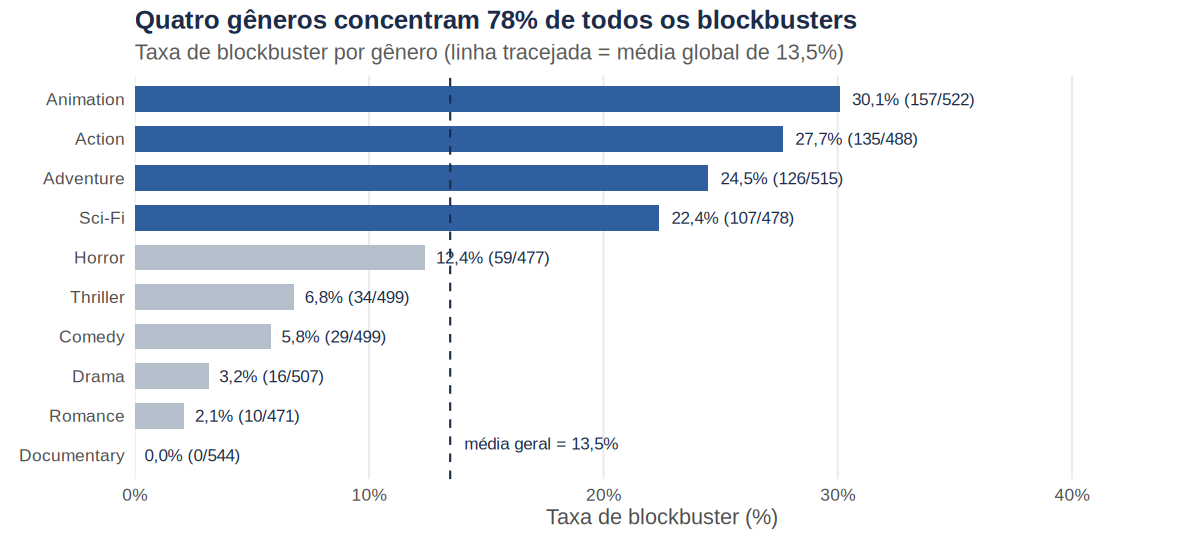

In [ ]:
# Tabela cruzada: gênero x blockbuster
tab_genero <- df %>%
  group_by(genre) %>%
  summarise(
    filmes       = n(),
    nao_bb       = sum(blockbuster == 0),
    blockbusters = sum(blockbuster == 1),
    taxa_bb_pct  = round(100 * mean(blockbuster), 2),
    orc_mediano  = mi(median(budget_usd)),
    pct_rev_3x   = round(100 * mean(revenue_usd > 3 * budget_usd), 1),
    roi_mediano  = round(median(roi), 2),
    .groups = "drop"
  ) %>%
  arrange(desc(taxa_bb_pct))
tab_genero

top4 <- c("Animation", "Action", "Adventure", "Sci-Fi")
cat("Participação dos 4 principais gêneros:",
    sum(df$genre %in% top4), "filmes (", br(100 * mean(df$genre %in% top4), 1), "% da base) e",
    sum(df$blockbuster[df$genre %in% top4]), "blockbusters (",
    br(100 * sum(df$blockbuster[df$genre %in% top4]) / sum(df$blockbuster), 1), "% do total).\n")

tab_genero %>%
  mutate(destaque = ifelse(taxa_bb_pct >= taxa_global, "Acima da média", "Abaixo da média")) %>%
  ggplot(aes(x = taxa_bb_pct, y = reorder(genre, taxa_bb_pct), fill = destaque)) +
  geom_col(width = 0.65) +
  geom_vline(xintercept = taxa_global, linetype = "dashed", color = TINTA, linewidth = 0.6) +
  annotate("text", x = taxa_global + 0.6, y = 1.3, hjust = 0, color = TINTA, size = 3.6,
           label = paste0("média geral = ", br(taxa_global, 1), "%")) +
  geom_text(aes(label = paste0(br(taxa_bb_pct, 1), "% (", blockbusters, "/", filmes, ")")),
            hjust = -0.1, color = TINTA, size = 3.6) +
  scale_fill_manual(values = c("Acima da média" = AZUL, "Abaixo da média" = CINZA), guide = "none") +
  scale_x_continuous(limits = c(0, 45), expand = c(0, 0), labels = function(x) paste0(x, "%")) +
  labs(title = "Quatro gêneros concentram 78% de todos os blockbusters",
       subtitle = "Taxa de blockbuster por gênero (linha tracejada = média global de 13,5%)",
       x = "Taxa de blockbuster (%)", y = NULL) +
  theme(panel.grid.major.y = element_blank(), panel.grid.major.x = element_line())

**Observações**

- **Três blocos muito bem separados** (todos com ~500 filmes, então a diferença não é efeito de tamanho amostral):
  - **Alta incidência (22% a 30%):** Animation (**30,1%**), Action (**27,7%**), Adventure (**24,5%**) e Sci-Fi (**22,4%**). Juntos, esses quatro gêneros correspondem a **40,1%** do catálogo, mas concentram **78,0%** de todos os blockbusters (525 de 673).
  - **Intermediário:** Horror (**12,4%**, 59 blockbusters), próximo da média global apesar de ter o segundo menor orçamento mediano (**US\$ 5,6 mi**). O motivo aparece nas últimas colunas da tabela: Horror tem o **maior ROI mediano da base (1,89)** e a maior parcela de filmes acima de 3× o orçamento (**48,4%**).
  - **Baixa incidência (0% a 7%):** Thriller (**6,8%**), Comedy (**5,8%**), Drama (**3,2%**), Romance (**2,1%**) e Documentary (**0,0%** — zero blockbusters em 544 filmes).
- **O gênero não é apenas um reflexo do orçamento:** Animation lidera a taxa de blockbuster (**30,1%**) com orçamento mediano (**US\$ 32,8 mi**) inferior ao de Sci-Fi (**US\$ 46,5 mi**), Action (**US\$ 40,1 mi**) e Adventure (**US\$ 37,5 mi**), porque combina orçamento alto com maior taxa de retorno (> 3× em 42,3% dos casos, contra 32,2% em Sci-Fi). Essa interação será aprofundada na seção 2.3.7.

### 2.3.3 Década e alvo: `decade` × `blockbuster` e estabilidade do orçamento

Aqui respondemos diretamente às duas perguntas deixadas pela seção 2.2: se a taxa de blockbuster muda ao longo das décadas e se o orçamento permanece comparável entre 1980s e 2020s (ou se há efeito de inflação na base).

decade,filmes,nao_bb,blockbusters,taxa_bb_pct,orc_Q1,orc_mediano,orc_Q3
<fct>,<int>,<int>,<int>,<dbl>,<chr>,<chr>,<chr>
1980s,1106,965,141,12.75,"US$ 5,4 mi","US$ 15,0 mi","US$ 42,3 mi"
1990s,1081,934,147,13.60,"US$ 4,6 mi","US$ 14,7 mi","US$ 41,1 mi"
2000s,1148,1003,145,12.63,"US$ 5,1 mi","US$ 14,3 mi","US$ 41,6 mi"
2010s,1079,918,161,14.92,"US$ 4,9 mi","US$ 15,4 mi","US$ 46,4 mi"
2020s,586,507,79,13.48,"US$ 6,0 mi","US$ 15,9 mi","US$ 39,0 mi"


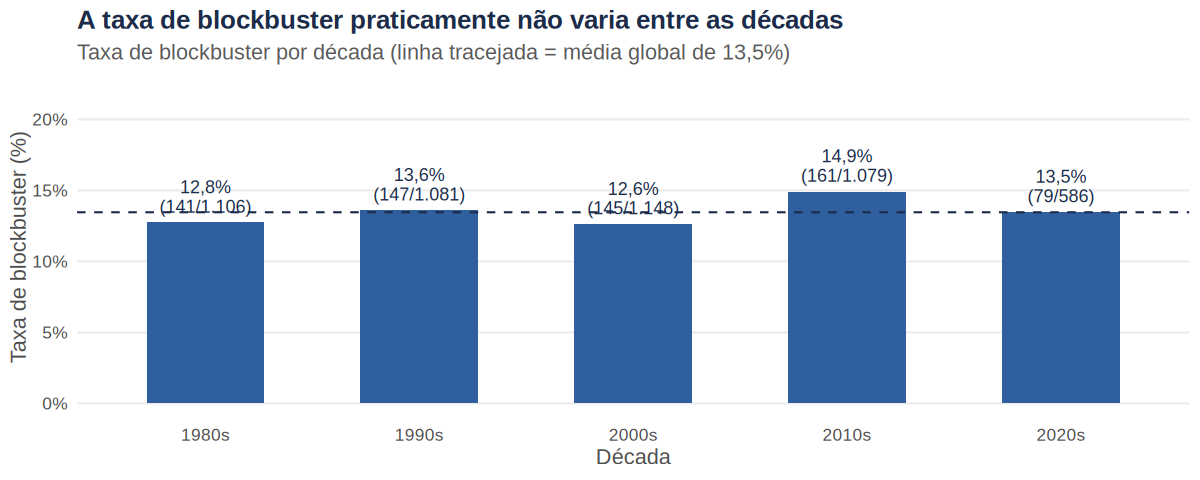

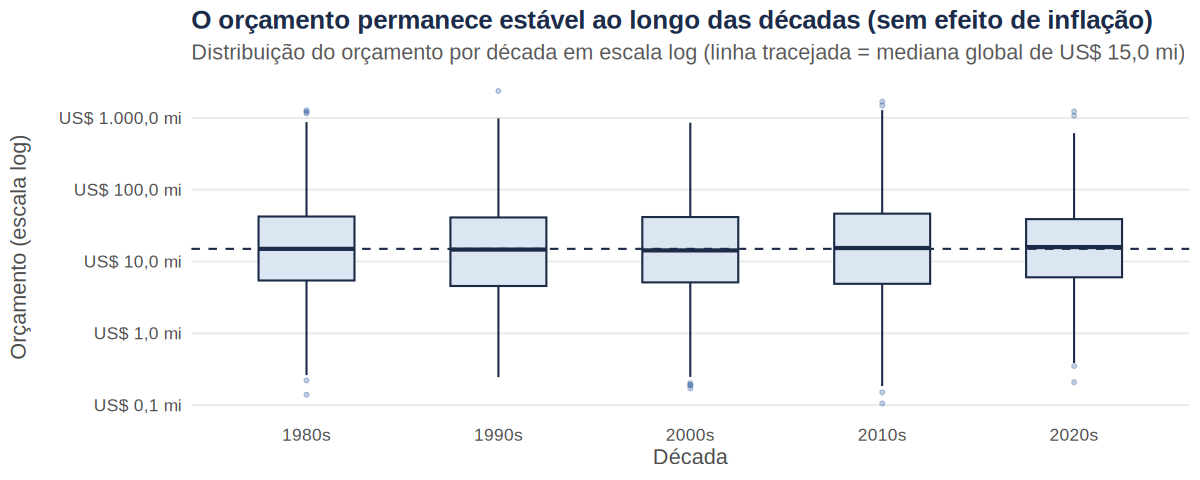

In [ ]:
# Tabela cruzada: década x blockbuster + quartis do orçamento por década
tab_decada <- df %>%
  group_by(decade) %>%
  summarise(
    filmes       = n(),
    nao_bb       = sum(blockbuster == 0),
    blockbusters = sum(blockbuster == 1),
    taxa_bb_pct  = round(100 * mean(blockbuster), 2),
    orc_Q1       = mi(quantile(budget_usd, 0.25)),
    orc_mediano  = mi(median(budget_usd)),
    orc_Q3       = mi(quantile(budget_usd, 0.75)),
    .groups = "drop"
  )
tab_decada

options(repr.plot.height = 4.0)
ggplot(tab_decada, aes(x = decade, y = taxa_bb_pct)) +
  geom_col(fill = AZUL, width = 0.55) +
  geom_hline(yintercept = taxa_global, linetype = "dashed", color = TINTA, linewidth = 0.6) +
  geom_text(aes(label = paste0(br(taxa_bb_pct, 1), "%\n(", blockbusters, "/", br(filmes), ")")),
            vjust = -0.3, color = TINTA, size = 3.8, lineheight = 0.9) +
  scale_y_continuous(limits = c(0, 22), labels = function(x) paste0(x, "%")) +
  labs(title = "A taxa de blockbuster praticamente não varia entre as décadas",
       subtitle = "Taxa de blockbuster por década (linha tracejada = média global de 13,5%)",
       x = "Década", y = "Taxa de blockbuster (%)")

ggplot(df, aes(x = decade, y = budget_usd)) +
  geom_boxplot(fill = "#DCE5F2", color = TINTA, outlier.color = AZUL,
               outlier.alpha = 0.3, outlier.size = 1.1, width = 0.5) +
  geom_hline(yintercept = median(df$budget_usd), linetype = "dashed", color = TINTA, linewidth = 0.6) +
  scale_y_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  labs(title = "O orçamento permanece estável ao longo das décadas (sem efeito de inflação)",
       subtitle = "Distribuição do orçamento por década em escala log (linha tracejada = mediana global de US$ 15,0 mi)",
       x = "Década", y = "Orçamento (escala log)")
options(repr.plot.height = 4.5)

**Observações**

- **Taxa de blockbuster estável no tempo:** a proporção oscila em uma faixa estreita, de **12,6% (2000s)** a **14,9% (2010s)**, sempre muito próxima da média global de **13,5%**. Não há tendência de alta nem de queda.
- **Orçamento comparável entre décadas (sem inflação):** a mediana varia apenas de **US\$ 14,3 mi** (2000s) a **US\$ 15,9 mi** (2020s), e os intervalos interquartis (Q1–Q3) praticamente coincidem nos cinco períodos. A correlação de Spearman entre `year` e `budget_usd` é quase zero (**0,012**). Como o dataset sintético não simulou inflação, **não é necessário deflacionar orçamentos** antes da modelagem.
- **Implicação para o modelo e testes:** `decade` aparece como a preditora mais fraca até aqui — excelente candidata a ser verificada formalmente via teste qui-quadrado na seção 3 (onde esperamos não rejeitar independência).

### 2.3.4 Duração e alvo: `runtime_min` × `blockbuster` e o efeito de confusão do gênero

Uma comparação direta sugere que blockbusters são mais longos, mas é importante verificar se esse efeito é próprio da duração ou se decorre apenas do fato de gêneros com mais blockbusters (como Sci-Fi, Action e Adventure) também terem filmes mais longos.

In [ ]:
# Visão marginal: duração por classe e por faixa
df_classe %>%
  group_by(classe) %>%
  summarise(
    filmes  = n(),
    Q1      = quantile(runtime_min, 0.25),
    mediana = median(runtime_min),
    media   = round(mean(runtime_min), 1),
    Q3      = quantile(runtime_min, 0.75),
    .groups = "drop"
  )

df %>%
  mutate(faixa_dur = cut(runtime_min, breaks = c(59, 90, 120, 150, 185),
                         labels = c("60–90 min", "91–120 min", "121–150 min", "151–185 min"))) %>%
  group_by(faixa_dur) %>%
  summarise(
    filmes       = n(),
    blockbusters = sum(blockbuster),
    taxa_bb_pct  = round(100 * mean(blockbuster), 2),
    orc_mediano  = mi(median(budget_usd)),
    .groups = "drop"
  )

# Controle por gênero: duração média por classe e correlação dentro de cada gênero
dur_genero <- df %>%
  group_by(genre) %>%
  summarise(
    med_dur_geral = median(runtime_min),
    media_bb      = if (sum(blockbuster) > 0) round(mean(runtime_min[blockbuster == 1]), 1) else NA_real_,
    media_nao_bb  = round(mean(runtime_min[blockbuster == 0]), 1),
    rho_dur_bb    = if (sum(blockbuster) > 0) round(cor(runtime_min, blockbuster, method = "spearman"), 3) else NA_real_,
    .groups = "drop"
  ) %>%
  arrange(desc(med_dur_geral))
dur_genero

classe,filmes,Q1,mediana,media,Q3
<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>
Blockbuster,673,98,117,115.0,132
Não blockbuster,4327,93,108,108.5,124


faixa_dur,filmes,blockbusters,taxa_bb_pct,orc_mediano
<fct>,<int>,<int>,<dbl>,<chr>
60–90 min,1060,101,9.53,"US$ 7,3 mi"
91–120 min,2327,267,11.47,"US$ 13,1 mi"
121–150 min,1467,276,18.81,"US$ 25,6 mi"
151–185 min,146,29,19.86,"US$ 37,1 mi"


genre,med_dur_geral,media_bb,media_nao_bb,rho_dur_bb
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Sci-Fi,136.0,135.4,135.3,0.022
Action,129.5,129.4,129.4,0.007
Adventure,126.0,126.5,125.5,0.030
Drama,119.0,116.1,119.6,-0.047
Thriller,110.0,106.5,110.1,-0.073
Romance,105.0,113.7,104.3,0.088
Comedy,100.0,98.3,99.5,-0.016
Animation,94.0,92.2,94.4,-0.055
Horror,94.0,94.1,94.2,0.007


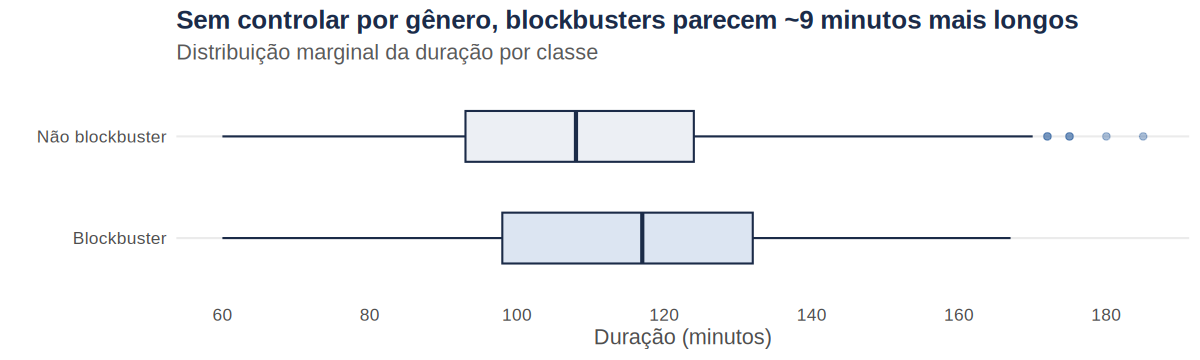

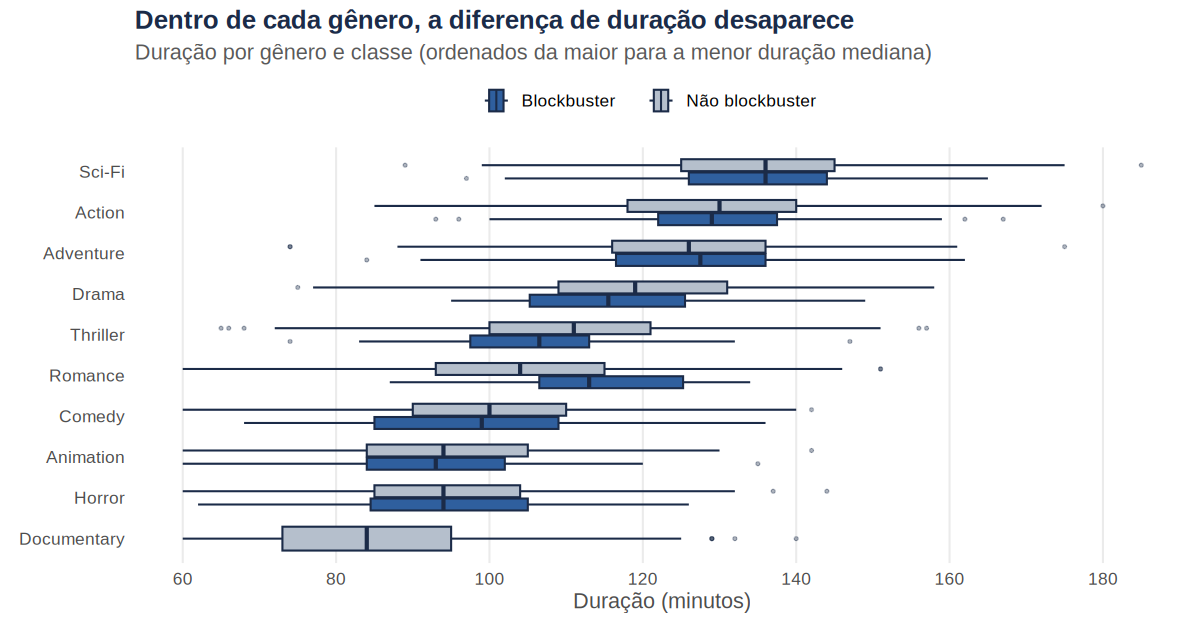

In [ ]:
options(repr.plot.height = 3.0)
ggplot(df_classe, aes(x = runtime_min, y = classe, fill = classe)) +
  geom_boxplot(color = TINTA, outlier.color = AZUL, outlier.alpha = 0.4, width = 0.5) +
  scale_fill_manual(values = c("Blockbuster" = "#DCE5F2", "Não blockbuster" = "#ECEFF4"), guide = "none") +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "Sem controlar por gênero, blockbusters parecem ~9 minutos mais longos",
       subtitle = "Distribuição marginal da duração por classe",
       x = "Duração (minutos)", y = NULL)

options(repr.plot.height = 5.2)
ordem_dur <- dur_genero$genre
df_classe %>%
  mutate(genre = factor(genre, levels = rev(ordem_dur))) %>%
  ggplot(aes(x = runtime_min, y = genre, fill = classe)) +
  geom_boxplot(color = TINTA, outlier.size = 0.8, outlier.alpha = 0.35, width = 0.65) +
  scale_fill_manual(values = c("Blockbuster" = AZUL, "Não blockbuster" = CINZA), name = NULL) +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "Dentro de cada gênero, a diferença de duração desaparece",
       subtitle = "Duração por gênero e classe (ordenados da maior para a menor duração mediana)",
       x = "Duração (minutos)", y = NULL) +
  theme(legend.position = "top",
        panel.grid.major.y = element_blank(), panel.grid.major.x = element_line())
options(repr.plot.height = 4.5)

**Observações**

- **Sinal marginal aparente:** olhando a base inteira, blockbusters têm duração mediana de **117 min** (média **115,0 min**) contra **108 min** (média **108,5 min**) dos não blockbusters, e a taxa sobe de **9,5%** (60–90 min) para **19,9%** (151–185 min). Note, porém, que o orçamento mediano também salta de **US\$ 7,3 mi** para **US\$ 37,1 mi** ao longo dessas faixas.
- **Efeito de confusão por gênero:** quando controlamos por `genre`, a diferença **desaparece completamente**. Dentro de cada categoria, as caixas de blockbusters e não blockbusters se sobrepõem quase ponto a ponto (por exemplo, Action: **129,4** vs **129,4 min**; Sci-Fi: **135,4** vs **135,3 min**; Horror: **94,1** vs **94,2 min**), e a correlação de Spearman dentro dos gêneros fica sempre próxima de zero (entre **−0,073 e +0,088**).
- **Causa do padrão:** na simulação, cada gênero tem sua própria faixa típica de duração — Sci-Fi (**136 min**), Action (**129,5 min**) e Adventure (**126 min**) são mais longos e também mais caros, enquanto Documentary (**84 min**) e Comedy (**100 min**) são curtos e baratos. A exceção é Animation, que é curto (**94 min**) e ainda assim tem a maior taxa de blockbuster.
- **Implicação para a árvore:** `runtime_min` age apenas como um *proxy* imperfeito de `genre`. Com `genre` presente no modelo, a duração tende a agregar muito pouco poder preditivo.

### 2.3.5 Relação entre orçamento e receita (*scatter*) e a fronteira do alvo

O gráfico de dispersão abaixo cruza `budget_usd` e `revenue_usd` em escala log-log, destacando a classe `blockbuster` e as duas retas que definem o alvo (`receita = US$ 100 mi` e `receita = 3 × orçamento`). Embora `revenue_usd` fique fora do modelo principal por causar vazamento, essa visualização esclarece o formato da relação financeira e explica o comportamento da taxa de blockbuster por faixa de orçamento.

Correlação de Spearman (orçamento x receita): 0,860 
Correlação de Pearson em escala log10:        0,866 


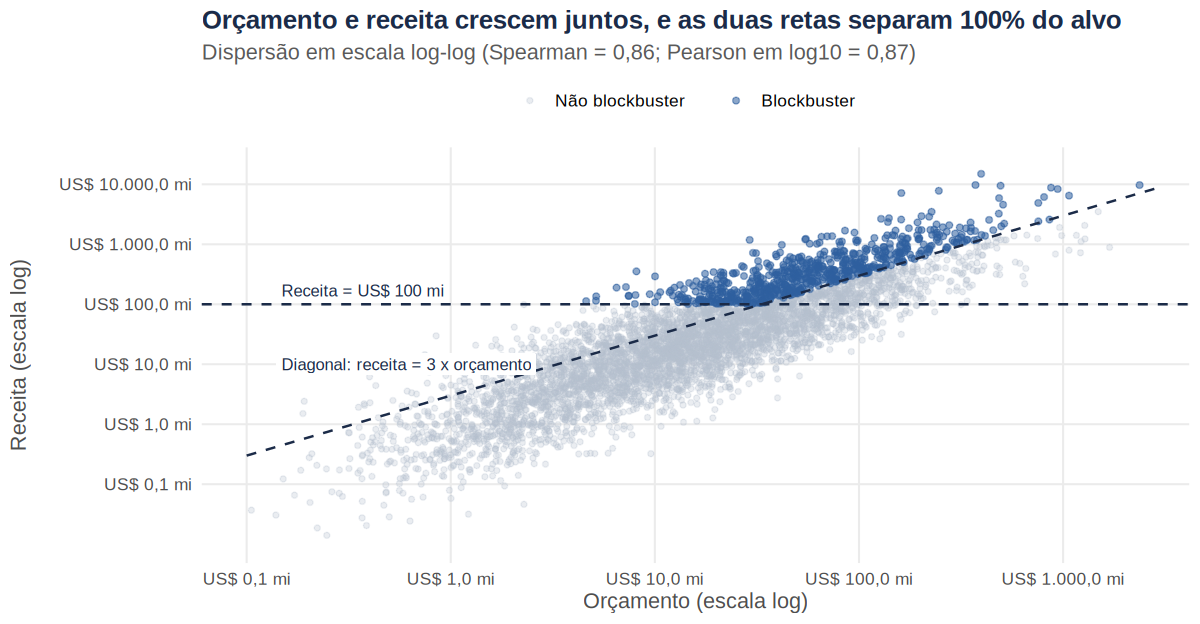

In [ ]:
rho_orc_rec <- cor(df$budget_usd, df$revenue_usd, method = "spearman")
r_log       <- cor(log10(df$budget_usd), log10(df$revenue_usd), method = "pearson")
cat("Correlação de Spearman (orçamento x receita):", br(rho_orc_rec, 3), "\n")
cat("Correlação de Pearson em escala log10:       ", br(r_log, 3), "\n")

linha_3x <- data.frame(
  budget_usd  = c(1e5, 3e9),
  revenue_usd = c(3e5, 9e9)
)

options(repr.plot.height = 5.2)
ggplot() +
  geom_point(data = filter(df_classe, blockbuster == 0),
             aes(x = budget_usd, y = revenue_usd, color = classe),
             alpha = 0.28, size = 1.3) +
  geom_point(data = filter(df_classe, blockbuster == 1),
             aes(x = budget_usd, y = revenue_usd, color = classe),
             alpha = 0.55, size = 1.5) +
  geom_hline(yintercept = 1e8, linetype = "dashed", color = TINTA, linewidth = 0.7) +
  geom_line(data = linha_3x, aes(x = budget_usd, y = revenue_usd),
            linetype = "dashed", color = TINTA, linewidth = 0.7) +
  annotate("label", x = 1.4e5, y = 1.7e8, hjust = 0, color = TINTA, fill = "white",
           linewidth = 0, size = 3.5, label = "Receita = US$ 100 mi") +
  annotate("label", x = 1.4e5, y = 1.0e7, hjust = 0, color = TINTA, fill = "white",
           linewidth = 0, size = 3.5, label = "Diagonal: receita = 3 x orçamento") +
  scale_color_manual(values = c("Blockbuster" = AZUL, "Não blockbuster" = CINZA), name = NULL) +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  scale_y_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9, 1e10)) +
  coord_cartesian(xlim = c(1e5, 2.5e9), ylim = c(1e4, 2e10)) +
  labs(title = "Orçamento e receita crescem juntos, e as duas retas separam 100% do alvo",
       subtitle = sprintf("Dispersão em escala log-log (Spearman = %s; Pearson em log10 = %s)",
                          br(rho_orc_rec, 2), br(r_log, 2)),
       x = "Orçamento (escala log)", y = "Receita (escala log)") +
  theme(legend.position = "top",
        panel.grid.major.x = element_line())
options(repr.plot.height = 4.5)

**Observações**

- **Relação positiva muito forte:** orçamento e receita caminham juntos em escala log-log (**Spearman = 0,860**; **Pearson em log10 = 0,866**). Ainda assim, há dispersão vertical expressiva: para um mesmo orçamento, a receita varia em mais de uma ordem de grandeza, o que explica por que o orçamento sozinho não determina perfeitamente o resultado.
- **Evidência visual do vazamento de informação:** todos os 673 pontos azuis ficam estritamente acima das duas retas tracejadas, sem um único ponto cinza nessa região. Incluir `revenue_usd`, `profit_usd` ou `roi` no modelo permitiria à árvore reconstruir quase mecanicamente essa fronteira (*data leakage*).
- **O ponto de inflexão em US\$ 33,3 mi:** o cruzamento das duas retas ocorre exatamente em `budget_usd = US$ 33,3 mi` (`receita = US$ 100 mi`). À esquerda desse ponto, muitos filmes cinzas superam a diagonal de 3× (591 filmes), mas ficam abaixo da reta horizontal de US\$ 100 mi; à direita, toda a separação é governada apenas pela diagonal de 3×.

### 2.3.6 Mapa de calor de correlações (Spearman)

Para ter uma visão conjunta de todas as variáveis numéricas — pré-lançamento, alvo, vazamento e pós-lançamento — calculamos a matriz de correlação de **Spearman**. Preferimos Spearman a Pearson porque orçamento, receita, votos e popularidade têm forte assimetria log-normal (seção 2.2), o que distorce a correlação linear de Pearson.

variavel,spearman,pearson
<chr>,<dbl>,<dbl>
Ano (pré),0.016,0.016
Duração (pré),0.101,0.100
Orçamento (pré),0.381,0.212
Receita (vaz.),0.547,0.401
Lucro (vaz.),0.571,0.402
ROI (vaz.),0.533,0.571
Nota (pós),-0.008,-0.013
Votos (pós),-0.005,-0.006
Popularidade (pós),0.012,0.000


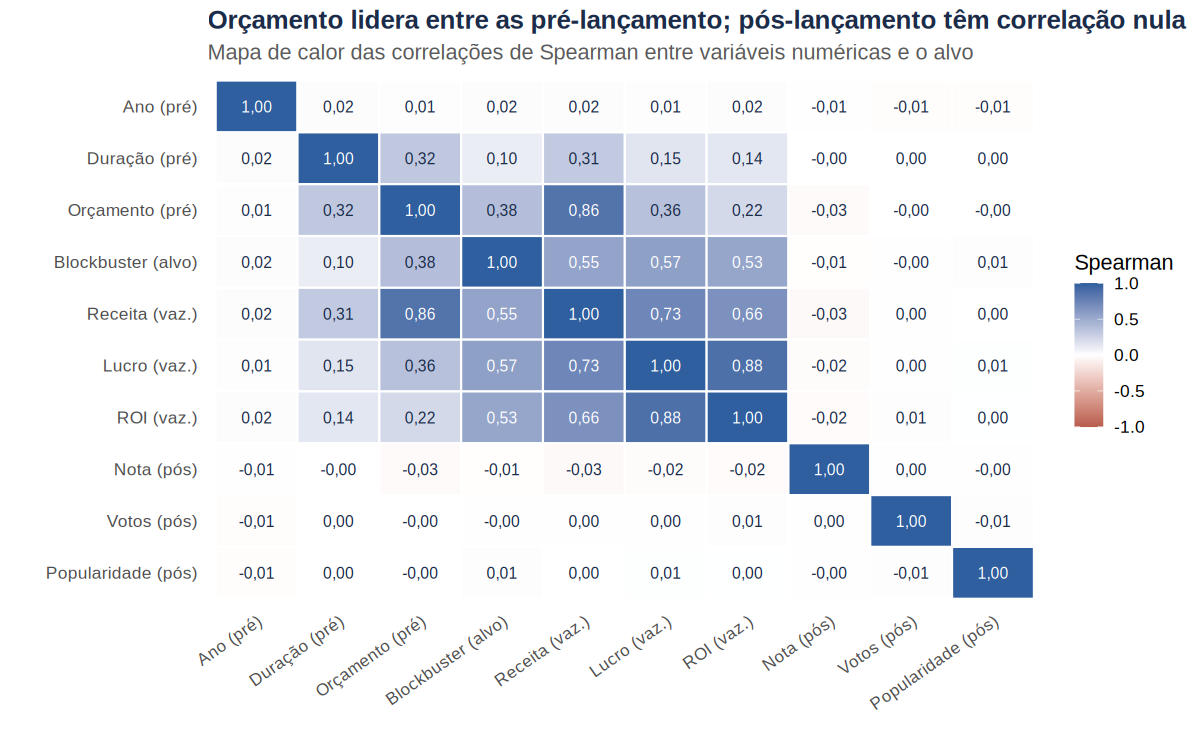

In [ ]:
vars_num <- c("year", "runtime_min", "budget_usd", "blockbuster",
              "revenue_usd", "profit_usd", "roi",
              "rating", "vote_count", "popularity")

rotulos_num <- c(
  year        = "Ano (pré)",
  runtime_min = "Duração (pré)",
  budget_usd  = "Orçamento (pré)",
  blockbuster = "Blockbuster (alvo)",
  revenue_usd = "Receita (vaz.)",
  profit_usd  = "Lucro (vaz.)",
  roi         = "ROI (vaz.)",
  rating      = "Nota (pós)",
  vote_count  = "Votos (pós)",
  popularity  = "Popularidade (pós)"
)

# Comparação Spearman vs Pearson com o alvo
outras <- vars_num[vars_num != "blockbuster"]
comp_cor <- data.frame(
  variavel = unname(rotulos_num[outras]),
  spearman = round(sapply(outras, function(v) cor(df[[v]], df$blockbuster, method = "spearman")), 3),
  pearson  = round(sapply(outras, function(v) cor(df[[v]], df$blockbuster, method = "pearson")), 3),
  row.names = NULL
)
comp_cor

# Matriz de correlação de Spearman para o heatmap
mat_cor <- cor(df[, vars_num], method = "spearman")
cor_df <- as.data.frame(as.table(mat_cor), stringsAsFactors = FALSE)
names(cor_df) <- c("v1", "v2", "cor")
cor_df <- cor_df %>%
  mutate(
    v1 = factor(rotulos_num[v1], levels = unname(rotulos_num)),
    v2 = factor(rotulos_num[v2], levels = rev(unname(rotulos_num)))
  )

options(repr.plot.height = 6.2)
ggplot(cor_df, aes(x = v1, y = v2, fill = cor)) +
  geom_tile(color = "white", linewidth = 0.6) +
  geom_text(aes(label = br(cor, 2),
                color = ifelse(abs(cor) >= 0.45, "claro", "escuro")),
            size = 3.3) +
  scale_fill_gradient2(low = "#B85D4E", mid = "white", high = AZUL,
                       midpoint = 0, limits = c(-1, 1), name = "Spearman") +
  scale_color_manual(values = c("claro" = "white", "escuro" = TINTA), guide = "none") +
  labs(title = "Orçamento lidera entre as pré-lançamento; pós-lançamento têm correlação nula",
       subtitle = "Mapa de calor das correlações de Spearman entre variáveis numéricas e o alvo",
       x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 35, hjust = 1),
        panel.grid  = element_blank())
options(repr.plot.height = 4.5)

**Observações**

- **Por que Spearman faz diferença:** para `budget_usd × blockbuster`, a correlação de Spearman é **0,381**, enquanto a de Pearson cai para **0,212** por causa dos valores extremos na cauda direita.
- **Bloco pré-lançamento:** `budget_usd` domina (**ρ = 0,381** com o alvo); `runtime_min` mostra associação fraca (**ρ = 0,101**) e está correlacionada com `budget_usd` (**ρ = 0,324**) pelo efeito de gênero visto na seção 2.3.4; `year` tem correlação praticamente zero com todas as variáveis (**|ρ| ≤ 0,017**).
- **Bloco de vazamento (`revenue_usd`, `profit_usd`, `roi`):** forma um quadrado fortemente correlacionado entre si (**ρ = 0,66 a 0,88**) e com o alvo (**ρ = 0,53 a 0,57**), confirmando por que não pode entrar no modelo principal.
- **Achado importante no bloco pós-lançamento (`rating`, `vote_count`, `popularity`):** todas as três variáveis têm correlação **praticamente nula** com `blockbuster` (**−0,008**, **−0,005** e **+0,012**) e com as variáveis financeiras (**|ρ| ≤ 0,035**). Na geração sintética do dataset, nota, votos e popularidade foram sorteados de forma independente da bilheteria. Isso antecipa um resultado interessante para o experimento de controle da seção 4: adicionar variáveis pós-lançamento tende a trazer **pouco ou nenhum ganho** em relação ao modelo pré-lançamento.

### 2.3.7 Análise multivariada: interação entre gênero, orçamento e década

Por fim, verificamos duas combinações simultâneas de preditoras: (1) se o efeito de `genre` se mantém quando fixamos a faixa de `budget_usd` — e se há interação entre os dois —, e (2) se o ranking dos gêneros muda entre décadas.

genre,< US$ 15 mi,US$ 15–50 mi,US$ 50 mi+
<fct>,<chr>,<chr>,<chr>
Animation,"5,2% (7/135)","33,8% (68/201)","44,1% (82/186)"
Action,"5,4% (5/93)","25,6% (46/180)","39,1% (84/215)"
Adventure,"3,7% (5/135)","26,7% (43/161)","35,6% (78/219)"
Sci-Fi,"1,2% (1/82)","22,9% (39/170)","29,6% (67/226)"
Horror,"3,5% (13/370)","40,4% (36/89)","55,6% (10/18)"
Thriller,"0,8% (2/261)","11,4% (19/166)","18,1% (13/72)"
Comedy,"0,0% (0/285)","9,8% (16/164)","26,0% (13/50)"
Drama,"0,0% (0/322)","8,0% (11/137)","10,4% (5/48)"
Romance,"0,0% (0/311)","4,9% (6/122)","10,5% (4/38)"


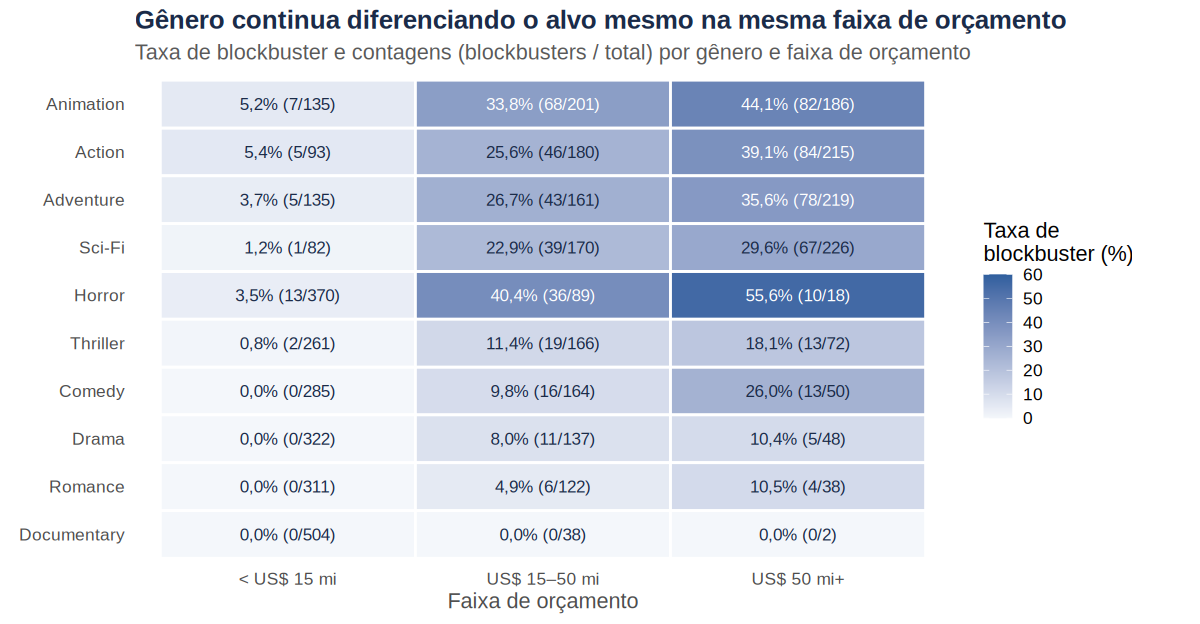

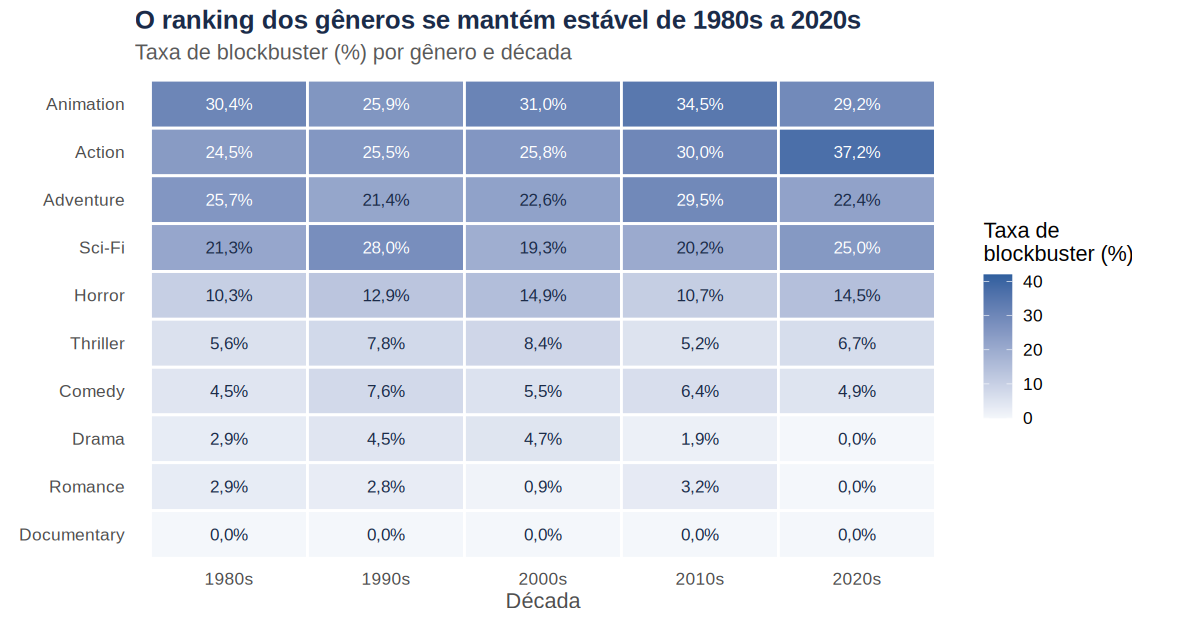

In [ ]:
ordem_gen <- tab_genero$genre

# Tabela cruzada multivariada: gênero x faixa de orçamento
tab_gen_orc <- df %>%
  mutate(faixa_orc = cut(
    budget_usd,
    breaks = c(0, 15e6, 50e6, Inf),
    labels = c("< US$ 15 mi", "US$ 15–50 mi", "US$ 50 mi+"),
    right = FALSE
  )) %>%
  group_by(genre, faixa_orc) %>%
  summarise(
    filmes       = n(),
    blockbusters = sum(blockbuster),
    taxa_bb_pct  = round(100 * mean(blockbuster), 1),
    .groups = "drop"
  )

# Tabela larga: taxa % (blockbusters / total)
tab_gen_orc %>%
  mutate(celula = paste0(br(taxa_bb_pct, 1), "% (", blockbusters, "/", filmes, ")")) %>%
  select(genre, faixa_orc, celula) %>%
  pivot_wider(names_from = faixa_orc, values_from = celula) %>%
  mutate(genre = factor(genre, levels = ordem_gen)) %>%
  arrange(genre)

# Heatmap 1: gênero x faixa de orçamento
options(repr.plot.height = 5.2)
tab_gen_orc %>%
  mutate(genre = factor(genre, levels = rev(ordem_gen))) %>%
  ggplot(aes(x = faixa_orc, y = genre, fill = taxa_bb_pct)) +
  geom_tile(color = "white", linewidth = 0.8) +
  geom_text(aes(label = paste0(br(taxa_bb_pct, 1), "% (", blockbusters, "/", filmes, ")"),
                color = ifelse(taxa_bb_pct >= 30, "claro", "escuro")),
            size = 3.6) +
  scale_fill_gradient(low = "#F4F7FB", high = AZUL, limits = c(0, 60),
                      name = "Taxa de\nblockbuster (%)") +
  scale_color_manual(values = c("claro" = "white", "escuro" = TINTA), guide = "none") +
  labs(title = "Gênero continua diferenciando o alvo mesmo na mesma faixa de orçamento",
       subtitle = "Taxa de blockbuster e contagens (blockbusters / total) por gênero e faixa de orçamento",
       x = "Faixa de orçamento", y = NULL) +
  theme(panel.grid = element_blank())

# Heatmap 2: gênero x década (estabilidade temporal)
tab_gen_dec <- df %>%
  group_by(genre, decade) %>%
  summarise(
    filmes       = n(),
    blockbusters = sum(blockbuster),
    taxa_bb_pct  = round(100 * mean(blockbuster), 1),
    .groups = "drop"
  )

tab_gen_dec %>%
  mutate(genre = factor(genre, levels = rev(ordem_gen))) %>%
  ggplot(aes(x = decade, y = genre, fill = taxa_bb_pct)) +
  geom_tile(color = "white", linewidth = 0.8) +
  geom_text(aes(label = paste0(br(taxa_bb_pct, 1), "%"),
                color = ifelse(taxa_bb_pct >= 24, "claro", "escuro")),
            size = 3.6) +
  scale_fill_gradient(low = "#F4F7FB", high = AZUL, limits = c(0, 42),
                      name = "Taxa de\nblockbuster (%)") +
  scale_color_manual(values = c("claro" = "white", "escuro" = TINTA), guide = "none") +
  labs(title = "O ranking dos gêneros se mantém estável de 1980s a 2020s",
       subtitle = "Taxa de blockbuster (%) por gênero e década",
       x = "Década", y = NULL) +
  theme(panel.grid = element_blank())
options(repr.plot.height = 4.5)

**Observações**

- **Orçamento e gênero atuam em conjunto — nenhum substitui o outro:** mesmo dentro da faixa mais cara (**US\$ 50 mi+**), a taxa de blockbuster varia drasticamente entre gêneros: **Animation (44,1%)**, **Action (39,1%)**, **Adventure (35,6%)** e **Sci-Fi (29,6%)** ficam muito acima de **Drama (10,4%)** e **Romance (10,5%)** (Documentary quase não aparece nessa faixa: apenas 2 filmes). Na faixa **< US\$ 15 mi**, por outro lado, **nenhum** gênero ultrapassa 5,4%.
- **Interação destacada — o caso de Horror:** na visão isolada (seção 2.3.2), Horror parecia mediano (**12,4%**) apenas porque **77,6%** dos filmes de terror custam menos de US\$ 15 mi (370 de 477), onde o piso de US\$ 100 mi impede quase todos de virarem blockbusters. Quando um filme de Horror tem orçamento maior, sua taxa dispara para **40,4%** (US\$ 15–50 mi, 36/89) e **55,6%** (US\$ 50 mi+, 10/18) — a mais alta de toda a tabela. Capturar interações desse tipo (*orçamento alto + gênero específico*) é exatamente uma das vantagens das **árvores de decisão**.
- **Estabilidade temporal (`genre` × `decade`):** a hierarquia dos gêneros se mantém consistente nas cinco décadas — os quatro líderes dominam em todos os períodos e Documentary tem **0%** em todos. Pequenas oscilações em 2020s (como Action em 37,2%) refletem células menores (43 a 65 filmes por gênero nessa década).
- **Ponto crítico para a seção 4 (modelagem):** com exceção do nicho pequeno de Horror ≥ US\$ 50 mi (apenas 18 filmes), **todas as combinações de gênero × orçamento ficam abaixo de 50%** de taxa de blockbuster (o máximo entre células grandes é Animation ≥ US\$ 50 mi, com **44,1%**). Isso indica que uma árvore CART com regra padrão de maioria (> 50%) pode gerar poucas ou nenhuma folha positiva, tornando fundamental avaliar pesos de classe, *prior* ou ajuste do limiar de probabilidade na modelagem.

## 2.4 Insights da EDA

### A EDA confirmou a hipótese e as expectativas do Projeto 1?

- **Expectativa sobre as variáveis principais — confirmada:** no Projeto 1, previmos que **orçamento e gênero** apareceriam nas primeiras divisões da árvore. A análise bivariada e multivariada confirma isso com folga: são as duas únicas preditoras pré-lançamento com sinal forte e complementar, e ainda apresentam interação clara (especialmente em Horror e Animation).
- **Expectativa sobre as demais preditoras — refinada:** `decade` quase não discrimina o alvo (12,6% a 14,9%) e não mostra inflação de orçamentos ao longo do tempo; já `runtime_min` aparenta efeito marginal (+9 min nos blockbusters), mas isso se mostrou um **efeito de confusão com `genre`** que desaparece dentro de cada categoria.
- **Perspectiva para H0 vs H1 do Projeto 1 (superar o *baseline* em F1):** há sinal estatístico real para distinguir perfis de altíssimo e baixíssimo risco — só o corte de orçamento < US\$ 15 mi já isola metade da base (2.498 filmes) com taxa de blockbuster de apenas 1,3%, e os gêneros Documentary, Romance e Drama ficam todos abaixo de 3,5%. No entanto, como a taxa nos melhores grupos grandes estabiliza entre **30% e 44%** (abaixo de 50%), a árvore só superará bem o *baseline* em F1 se o **desbalanceamento (13,5%)** for tratado adequadamente na seção 4 (por exemplo, ajustando limiar de decisão, pesos de classe ou parâmetros de poda).
- **Surpresa para os experimentos de controle:** enquanto `revenue_usd`, `profit_usd` e `roi` separam perfeitamente o alvo por definição (vazamento visualizado no *scatter*), as variáveis pós-lançamento (`rating`, `vote_count` e `popularity`) têm **correlação nula** com `blockbuster` e com a receita (**|ρ| ≤ 0,035**). Logo, espera-se que elas não melhorem o desempenho do modelo no experimento de controle.

### Quais variáveis são promissoras?

| Variável / Grupo | Papel | Força do sinal | Achado principal na EDA | Expectativa para a árvore (seção 4) |
|---|---|---|---|---|
| `budget_usd` | Preditora (pré) | **Forte** (ρ = 0,381) | Mediana 4,4× maior nos blockbusters (US\$ 52,4 vs US\$ 11,8 mi); 95,1% dos blockbusters custam ≥ US\$ 15 mi | **Primeira ou segunda divisão**; corta a faixa de baixo orçamento |
| `genre` | Preditora (pré) | **Forte** (0% a 30,1%) | Top 4 (Animation, Action, Adventure, Sci-Fi) concentram 78% dos blockbusters; interage com orçamento (destaque para Horror) | **Primeira ou segunda divisão**, em interação com `budget_usd` |
| `runtime_min` | Preditora (pré) | **Fraca / confundida** (ρ = 0,101; ≈ 0 por gênero) | Diferença marginal (+9 min) desaparece dentro de cada gênero; age como *proxy* de `genre` | Pouco útil quando `genre` já está na árvore |
| `decade` | Preditora (pré) | **Nula / muito fraca** (12,6% a 14,9%) | Taxa de blockbuster e orçamento mediano (~US\$ 15 mi) estáveis de 1980s a 2020s | Provavelmente ausente nos níveis rasos (profundidade < 4) |
| `revenue_usd`, `profit_usd`, `roi` | Excluídas (vazamento) | **Determinística** (ρ = 0,53 a 0,57) | Definem a fronteira exata do alvo (`> 3×` e `> US$ 100 mi`) | Apenas no experimento de controle de *data leakage* |
| `rating`, `vote_count`, `popularity` | Excluídas (pós) | **Nula** (\|ρ\| ≤ 0,012) | Independentes da bilheteria no gerador sintético | Experimento de controle deve mostrar ganho desprezível |

### Ponte para a Seção 3 (Testes de Hipóteses)

Os padrões encontrados na EDA sugerem quatro verificações formais para a seção 3 (com nível de significância α = 5%), atentando aos pressupostos de normalidade já sinalizados na seção 2.2:

1. **Orçamento (`budget_usd` × `blockbuster`):** testar se o orçamento de blockbusters difere (ou é maior) que o de não blockbusters. Como `budget_usd` é fortemente assimétrica (log-normal), verificar normalidade (`shapiro.test`) e aplicar teste não paramétrico (**Wilcoxon / Mann-Whitney**), esperando forte rejeição de $H_0$.
2. **Gênero (`genre` × `blockbuster`):** testar independência entre gênero e ser blockbuster via **teste Qui-quadrado de independência ($\chi^2$)**, esperando rejeição clara de $H_0$.
3. **Década (`decade` × `blockbuster`):** testar independência entre década e blockbuster via **Qui-quadrado ($\chi^2$)** — aqui a expectativa é **não rejeitar $H_0$**, confirmando formalmente que a década não diferencia o alvo (e opcionalmente verificar por Kruskal-Wallis que a distribuição do orçamento não muda entre décadas).
4. **Duração (`runtime_min` × `blockbuster`):** testar a diferença marginal de duração (checando normalidade; Mann-Whitney) e contrapor ao resultado estratificado por gênero, evidenciando que significância estatística marginal pode ser fruto de confusão por outra variável.

# 3. Validação Estatística (Teste de Hipóteses)

A EDA (seção 2) levantou padrões que aqui são verificados formalmente. Todos os testes usam **nível de significância α = 5%**: se p < 0,05, rejeitamos H0.

> As hipóteses H0/H1 do Projeto 1 (a árvore supera o *baseline* em F1?) dependem do modelo e serão avaliadas na seção 5. Esta seção testa as **relações entre as variáveis e o alvo** que sustentam a escolha das preditoras.

## 3.1 Definição das Hipóteses

| # | Pergunta (origem na EDA) | H0 | H1 | Resultado esperado pela EDA |
|---|---|---|---|---|
| T1 | O orçamento é maior nos blockbusters? (2.3.1) | O orçamento dos blockbusters **não é maior** que o dos demais | O orçamento dos blockbusters é **estocasticamente maior** | Rejeitar H0 |
| T2 | O gênero está associado ao alvo? (2.3.2) | `genre` e `blockbuster` são **independentes** | Há **associação** | Rejeitar H0 |
| T3 | A década está associada ao alvo? (2.3.3) | `decade` e `blockbuster` são **independentes** | Há **associação** | **Não** rejeitar H0 |
| T3b | O orçamento mudou entre décadas (inflação)? (2.3.3) | A distribuição do orçamento é **igual** nas 5 décadas | Pelo menos uma década **difere** | **Não** rejeitar H0 |
| T4 | A duração difere entre as classes? (2.3.4) | As distribuições de duração são **iguais** | **Diferem** | Rejeitar H0 na visão marginal |
| T4b | A duração ainda importa **dentro do gênero**? (2.3.4) | `runtime_min` **não** melhora o modelo, dado `genre` | Melhora | **Não** rejeitar H0 (efeito de confusão) |
| T5 | Nota, votos e popularidade diferem entre as classes? (2.3.6) | Distribuições **iguais** | **Diferem** | **Não** rejeitar H0 (correlação nula) |

**Notação formal.** Sejam $X_{bb}$ e $X_{não}$ o valor da variável para um filme sorteado ao acaso entre os blockbusters e entre os demais, e $\pi_k = P(\text{blockbuster} \mid \text{grupo } k)$.

- **T1:** $H_0: P(X_{bb} > X_{não}) \le 0{,}5$ vs. $H_1: P(X_{bb} > X_{não}) > 0{,}5$ (unilateral, `budget_usd`).
- **T2 e T3:** $H_0: \pi_1 = \pi_2 = \dots = \pi_K$ (a taxa de blockbuster é a mesma em todos os gêneros / décadas) vs. $H_1$: pelo menos uma $\pi_k$ difere.
- **T3b:** $H_0: F_{1980s} = \dots = F_{2020s}$ (mesma distribuição de orçamento) vs. $H_1$: pelo menos uma difere.
- **T4 e T5:** $H_0: P(X_{bb} > X_{não}) = 0{,}5$ vs. $H_1: P(X_{bb} > X_{não}) \ne 0{,}5$ (bilateral).
- **T4b:** no modelo logístico $\text{logit}(\pi) = \beta_0 + \text{gênero} + \beta_{dur}\cdot\text{runtime\_min}$, $H_0: \beta_{dur} = 0$ vs. $H_1: \beta_{dur} \ne 0$.

**Múltiplos testes.** Para os testes em que esperamos **rejeitar** H0, usamos a correção de **Holm** como proteção contra falsos positivos. Para os testes em que esperamos **não rejeitar**, a correção jogaria a favor da nossa conclusão (ela aumenta o p-valor), então nesses casos o critério é o **p-valor sem ajuste**, que é o mais exigente.

In [ ]:
alpha <- 0.05
fmt_p   <- function(p) ifelse(p < 0.001, "< 0,001", br(p, 3))
decisao <- function(p, a = alpha) ifelse(p < a, "Rejeita H0", "Não rejeita H0")

# cópia local: não altera o df usado na modelagem (seção 4)
dados_t <- df
dados_t$classe <- factor(ifelse(dados_t$blockbuster == 1, "Blockbuster", "Não blockbuster"),
                         levels = c("Blockbuster", "Não blockbuster"))

# Shapiro-Wilk por grupo (limite do R: 3 <= n <= 5000)
checa_norm <- function(x, g, nome) {
  do.call(rbind, lapply(levels(g), function(l) {
    s <- shapiro.test(x[g == l])
    data.frame(variavel = nome, grupo = l, n = sum(g == l),
               W = round(unname(s$statistic), 4), p_valor = fmt_p(s$p.value),
               normal_a_5pct = ifelse(s$p.value >= alpha, "sim", "não"))
  }))
}

## 3.2 Escolha e Execução do Teste

### T1. Orçamento × blockbuster

**Escolha do teste.** O teste t compara médias e exige normalidade em cada grupo (ou n grande com distribuição não muito assimétrica). A EDA mostrou que o orçamento é fortemente assimétrico (assimetria 8,7). Verificamos a normalidade com **Shapiro-Wilk** (H0: os dados vêm de uma normal), tanto na escala original quanto em log10.

variavel,grupo,n,W,p_valor,normal_a_5pct
<chr>,<chr>,<int>,<dbl>,<chr>,<chr>
budget_usd,Blockbuster,673,0.4753,"< 0,001",não
budget_usd,Não blockbuster,4327,0.3505,"< 0,001",não
log10(budget_usd),Blockbuster,673,0.9894,"< 0,001",não
log10(budget_usd),Não blockbuster,4327,0.9992,"0,054",sim


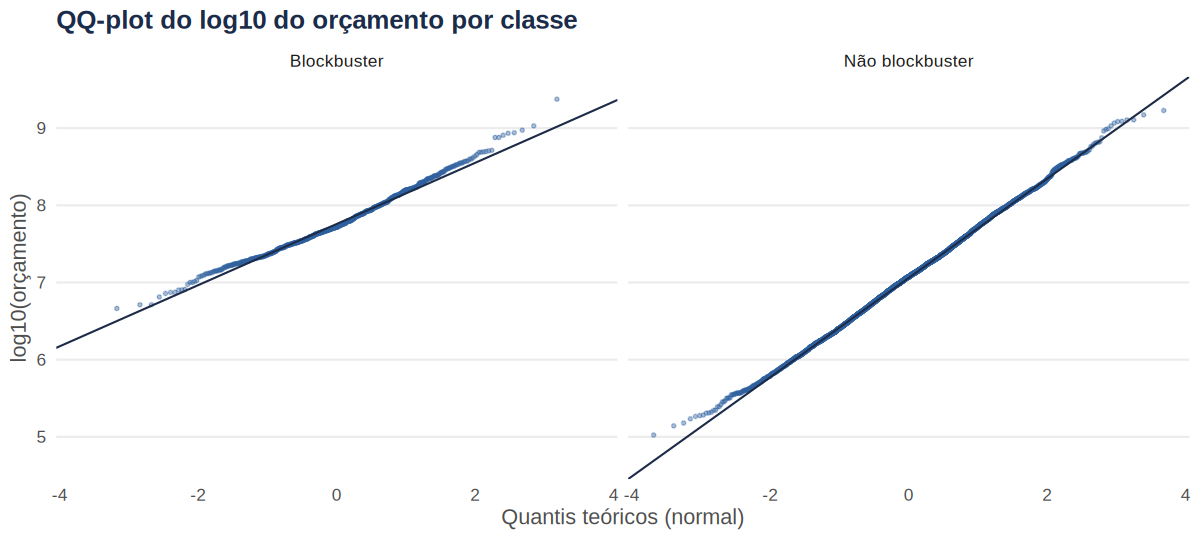

In [ ]:
norm_orc <- rbind(
  checa_norm(dados_t$budget_usd,        dados_t$classe, "budget_usd"),
  checa_norm(log10(dados_t$budget_usd), dados_t$classe, "log10(budget_usd)")
)
norm_orc

ggplot(dados_t, aes(sample = log10(budget_usd))) +
  stat_qq(color = AZUL, alpha = 0.4, size = 0.8) + stat_qq_line(color = TINTA) +
  facet_wrap(~ classe) +
  labs(title = "QQ-plot do log10 do orçamento por classe",
       x = "Quantis teóricos (normal)", y = "log10(orçamento)")

**Decisão.** Na escala original, a normalidade é rejeitada nos dois grupos (p < 0,001). Em log10, o grupo **não blockbuster** é compatível com a normal (W = 0,999; p = 0,054), e o QQ-plot fica praticamente sobre a reta. Já o grupo **blockbuster** não é (W = 0,989; p < 0,001): o QQ-plot faz uma curva suave, com as duas caudas acima da reta. Isso tem uma explicação: para ser blockbuster, o filme precisa faturar mais de US\$ 100 mi, então orçamentos muito baixos quase nunca entram nesse grupo, e a cauda esquerda da distribuição fica cortada.

Como o pressuposto de normalidade não vale nos dois grupos, o teste principal é o **Wilcoxon-Mann-Whitney unilateral**, que não exige normalidade e é robusto a outliers. Como verificação de robustez, rodamos o **t de Welch em log10**: com 673 e 4.327 filmes, o Teorema Central do Limite torna o teste t pouco sensível a esse desvio moderado.

In [ ]:
w1 <- wilcox.test(budget_usd ~ classe, data = dados_t,
                  alternative = "greater", exact = FALSE)

n1 <- sum(dados_t$blockbuster == 1); n0 <- sum(dados_t$blockbuster == 0)
prob_sup <- unname(w1$statistic) / (n1 * n0)   # P(orçamento_bb > orçamento_não_bb)

t1_welch <- t.test(log10(budget_usd) ~ classe, data = dados_t, alternative = "greater")

data.frame(
  teste   = c("Wilcoxon-Mann-Whitney (unilateral)", "t de Welch em log10 (robustez)"),
  p_valor = c(fmt_p(w1$p.value), fmt_p(t1_welch$p.value)),
  decisao = decisao(c(w1$p.value, t1_welch$p.value))
)
cat("Probabilidade de superioridade (P[orç. blockbuster > orç. não blockbuster]):",
    br(prob_sup, 3), "\n")
cat("Correlação rank-biserial:", br(2 * prob_sup - 1, 3), "\n")

teste,p_valor,decisao
<chr>,<chr>,<chr>
Wilcoxon-Mann-Whitney (unilateral),"< 0,001",Rejeita H0
t de Welch em log10 (robustez),"< 0,001",Rejeita H0


Probabilidade de superioridade (P[orç. blockbuster > orç. não blockbuster]): 0,822 
Correlação rank-biserial: 0,644 


### T2 e T3. Gênero e década × blockbuster (independência)

**Escolha do teste.** Ambas as variáveis são categóricas, então usamos o **qui-quadrado de independência**. O pressuposto é que as frequências esperadas sejam ≥ 5 em (quase) todas as células; verificamos abaixo. Como o p-valor depende do tamanho da amostra, reportamos também o **V de Cramér** (tamanho do efeito) e os **resíduos padronizados** (|resíduo| > 2 indica células que mais contribuem para a associação).

In [ ]:
testa_qui2 <- function(var, nome) {
  tab <- table(dados_t[[var]], dados_t$blockbuster, dnn = c(var, "blockbuster"))
  x2  <- chisq.test(tab)
  v   <- sqrt(unname(x2$statistic) / (sum(tab) * (min(dim(tab)) - 1)))
  list(tab = tab, x2 = x2, V = v,
       resumo = data.frame(teste = paste("Qui-quadrado:", nome),
                           X2 = round(unname(x2$statistic), 2), gl = unname(x2$parameter),
                           p_valor = fmt_p(x2$p.value), V_Cramer = round(v, 3),
                           min_esperado = round(min(x2$expected), 1),
                           decisao = decisao(x2$p.value)))
}

t2 <- testa_qui2("genre",  "gênero × blockbuster")
t3 <- testa_qui2("decade", "década × blockbuster")
rbind(t2$resumo, t3$resumo)

# Resíduos padronizados (quais gêneros pesam mais)
round(t2$x2$stdres, 2)

teste,X2,gl,p_valor,V_Cramer,min_esperado,decisao
<chr>,<dbl>,<int>,<chr>,<dbl>,<dbl>,<chr>
Qui-quadrado: gênero × blockbuster,521.77,9,"< 0,001",0.323,63.4,Rejeita H0
Qui-quadrado: década × blockbuster,3.15,4,"0,532",0.025,78.9,Não rejeita H0


             blockbuster
genre              0      1
  Action       -9.68   9.68
  Adventure    -7.73   7.73
  Animation   -11.75  11.75
  Comedy        5.28  -5.28
  Documentary   9.74  -9.74
  Drama         7.17  -7.17
  Horror        0.73  -0.73
  Romance       7.57  -7.57
  Sci-Fi       -6.01   6.01
  Thriller      4.58  -4.58

**Complemento do T3 (inflação).** Para a pergunta T3b, o orçamento (assimétrico, 5 grupos) é comparado entre décadas com **Kruskal-Wallis** (alternativa não paramétrica à ANOVA). Também usamos a correlação de Spearman entre ano e orçamento.

In [ ]:
t3b <- kruskal.test(budget_usd ~ decade, data = dados_t)
t3c <- cor.test(dados_t$year, dados_t$budget_usd, method = "spearman", exact = FALSE)

data.frame(
  teste   = c("Kruskal-Wallis: orçamento por década", "Spearman: ano × orçamento"),
  estatistica = c(paste0("H = ", br(unname(t3b$statistic), 2)),
                  paste0("rho = ", br(unname(t3c$estimate), 3))),
  p_valor = c(fmt_p(t3b$p.value), fmt_p(t3c$p.value)),
  decisao = decisao(c(t3b$p.value, t3c$p.value))
)

teste,estatistica,p_valor,decisao
<chr>,<chr>,<chr>,<chr>
Kruskal-Wallis: orçamento por década,"H = 1,52","0,824",Não rejeita H0
Spearman: ano × orçamento,"rho = 0,012","0,401",Não rejeita H0


### T4 e T4b. Duração × blockbuster

**Escolha do teste.** A duração parece simétrica (seção 2.2.3), mas o Shapiro rejeitou normalidade na EDA. Verificamos por grupo e adotamos o Wilcoxon bilateral caso a normalidade seja rejeitada.

In [ ]:
norm_dur <- checa_norm(dados_t$runtime_min, dados_t$classe, "runtime_min")
norm_dur

t4 <- wilcox.test(runtime_min ~ classe, data = dados_t, exact = FALSE, conf.int = TRUE)
data.frame(teste = "Wilcoxon bilateral: duração por classe (marginal)",
           p_valor = fmt_p(t4$p.value), decisao = decisao(t4$p.value),
           mediana_bb = median(dados_t$runtime_min[dados_t$blockbuster == 1]),
           mediana_nao_bb = median(dados_t$runtime_min[dados_t$blockbuster == 0]),
           # Hodges-Lehmann: deslocamento típico (em minutos) entre as classes, com IC 95%
           deslocamento_min = round(unname(t4$estimate), 1),
           IC95 = paste0("[", br(t4$conf.int[1], 1), "; ", br(t4$conf.int[2], 1), "]"))

variavel,grupo,n,W,p_valor,normal_a_5pct
<chr>,<chr>,<int>,<dbl>,<chr>,<chr>
runtime_min,Blockbuster,673,0.9870,"< 0,001",não
runtime_min,Não blockbuster,4327,0.9948,"< 0,001",não


teste,p_valor,decisao,mediana_bb,mediana_nao_bb,deslocamento_min,IC95
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
Wilcoxon bilateral: duração por classe (marginal),"< 0,001",Rejeita H0,117,108,7,"[5,0; 9,0]"


**T4b: o efeito marginal sobrevive ao controle por gênero?** A EDA indicou que a diferença de ~9 min decorre de os gêneros com mais blockbusters terem filmes mais longos (efeito de confusão). Testamos de duas formas, excluindo Documentary (0 blockbusters, o que causaria separação perfeita no modelo logístico):

1. **Wilcoxon dentro de cada gênero**, com correção de **Holm** para os 9 testes simultâneos;
2. **Teste da razão de verossimilhanças (LRT)** no modelo logístico: `runtime_min` melhora o ajuste dado `genre`? E dado `genre` + `log10(budget)`?

In [ ]:
sem_doc <- droplevels(subset(dados_t, genre != "Documentary"))

t4b_gen <- sem_doc %>%
  group_by(genre) %>%
  summarise(n_bb = sum(blockbuster),
            p = wilcox.test(runtime_min[blockbuster == 1],
                            runtime_min[blockbuster == 0], exact = FALSE)$p.value,
            .groups = "drop") %>%
  mutate(p_holm = p.adjust(p, method = "holm"),
         decisao_p_bruto = decisao(p),        # critério mais exigente para "não rejeitar"
         decisao_holm    = decisao(p_holm),
         p = fmt_p(p), p_holm = fmt_p(p_holm))
t4b_gen

m0 <- glm(blockbuster ~ genre,                      data = sem_doc, family = binomial)
m1 <- glm(blockbuster ~ genre + runtime_min,        data = sem_doc, family = binomial)
m2 <- glm(blockbuster ~ genre + log10(budget_usd),  data = sem_doc, family = binomial)
m3 <- glm(blockbuster ~ genre + log10(budget_usd) + runtime_min, data = sem_doc, family = binomial)

lrt_a <- anova(m0, m1, test = "Chisq")   # duração dado gênero
lrt_b <- anova(m2, m3, test = "Chisq")   # duração dado gênero + orçamento
p_lrt_a <- lrt_a$`Pr(>Chi)`[2]; p_lrt_b <- lrt_b$`Pr(>Chi)`[2]

data.frame(teste = c("LRT: runtime | genre", "LRT: runtime | genre + orçamento"),
           p_valor = fmt_p(c(p_lrt_a, p_lrt_b)),
           decisao = decisao(c(p_lrt_a, p_lrt_b)))

genre,n_bb,p,p_holm,decisao_p_bruto,decisao_holm
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Action,135,"0,880","1,000",Não rejeita H0,Não rejeita H0
Adventure,126,"0,495","1,000",Não rejeita H0,Não rejeita H0
Animation,157,"0,210","1,000",Não rejeita H0,Não rejeita H0
Comedy,29,"0,714","1,000",Não rejeita H0,Não rejeita H0
Drama,16,"0,295","1,000",Não rejeita H0,Não rejeita H0
Horror,59,"0,879","1,000",Não rejeita H0,Não rejeita H0
Romance,10,"0,056","0,506",Não rejeita H0,Não rejeita H0
Sci-Fi,107,"0,624","1,000",Não rejeita H0,Não rejeita H0
Thriller,34,"0,106","0,845",Não rejeita H0,Não rejeita H0


teste,p_valor,decisao
<chr>,<chr>,<chr>
LRT: runtime | genre,"0,476",Não rejeita H0
LRT: runtime | genre + orçamento,"0,770",Não rejeita H0


### T5. Variáveis pós-lançamento × blockbuster

Nota, votos e popularidade são assimétricas (seção 2.2.6), então usamos **Wilcoxon bilateral**, com **Holm** para os 3 testes. A EDA indica correlação nula com o alvo.

In [ ]:
pos <- c("rating", "vote_count", "popularity")
t5 <- do.call(rbind, lapply(pos, function(v) {
  w <- wilcox.test(dados_t[[v]] ~ dados_t$classe, exact = FALSE)
  data.frame(variavel = v, p = w$p.value)
}))
t5$p_holm <- p.adjust(t5$p, "holm")
t5 %>% mutate(decisao_p_bruto = decisao(p), decisao_holm = decisao(p_holm),
              p = fmt_p(p), p_holm = fmt_p(p_holm))

variavel,p,p_holm,decisao_p_bruto,decisao_holm
<chr>,<chr>,<chr>,<chr>,<chr>
rating,"0,549","1,000",Não rejeita H0,Não rejeita H0
vote_count,"0,749","1,000",Não rejeita H0,Não rejeita H0
popularity,"0,395","1,000",Não rejeita H0,Não rejeita H0


In [ ]:
resumo_testes <- data.frame(
  id = c("T1", "T2", "T3", "T3b", "T4", "T4b (LRT, gênero)", "T4b (LRT, gênero+orç.)"),
  teste = c("Wilcoxon unilateral", "Qui-quadrado", "Qui-quadrado", "Kruskal-Wallis",
            "Wilcoxon bilateral", "LRT logístico", "LRT logístico"),
  p = c(w1$p.value, t2$x2$p.value, t3$x2$p.value, t3b$p.value,
        t4$p.value, p_lrt_a, p_lrt_b)
)
resumo_testes$esperado <- c("Rejeitar", "Rejeitar", "Não rejeitar", "Não rejeitar",
                            "Rejeitar", "Não rejeitar", "Não rejeitar")   # previsão da 3.1
resumo_testes$p_holm  <- p.adjust(resumo_testes$p, "holm")   # família de 7 testes principais
# Rejeições: valem com Holm. Não rejeições: valem com o p bruto (mais exigente).
resumo_testes$decisao_p_bruto <- decisao(resumo_testes$p)
resumo_testes$decisao_holm    <- decisao(resumo_testes$p_holm)
resumo_testes %>% mutate(p = fmt_p(p), p_holm = fmt_p(p_holm))

id,teste,p,esperado,p_holm,decisao_p_bruto,decisao_holm
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
T1,Wilcoxon unilateral,"< 0,001",Rejeitar,"< 0,001",Rejeita H0,Rejeita H0
T2,Qui-quadrado,"< 0,001",Rejeitar,"< 0,001",Rejeita H0,Rejeita H0
T3,Qui-quadrado,"0,532",Não rejeitar,"1,000",Não rejeita H0,Não rejeita H0
T3b,Kruskal-Wallis,"0,824",Não rejeitar,"1,000",Não rejeita H0,Não rejeita H0
T4,Wilcoxon bilateral,"< 0,001",Rejeitar,"< 0,001",Rejeita H0,Rejeita H0
"T4b (LRT, gênero)",LRT logístico,"0,476",Não rejeitar,"1,000",Não rejeita H0,Não rejeita H0
"T4b (LRT, gênero+orç.)",LRT logístico,"0,770",Não rejeitar,"1,000",Não rejeita H0,Não rejeita H0


## 3.3 Interpretação do p-valor

**Regra de decisão (α = 5%):** p < 0,05 → rejeitamos H0; p ≥ 0,05 → não rejeitamos H0. Não rejeitar **não prova** que H0 é verdadeira; significa apenas que os dados não trazem evidência suficiente contra ela. Como definido na 3.1, as rejeições são confirmadas com o p ajustado por Holm, e as não rejeições com o p sem ajuste.

| Teste | Resultado | p-valor | Tamanho do efeito | Decisão | Bate com a EDA? |
|---|---|---|---|---|---|
| T1 – orçamento | Blockbusters custam mais | < 0,001 | P(sup.) = 0,822; rank-biserial = 0,644 | Rejeita H0 | Sim |
| T2 – gênero | Gênero e alvo associados | < 0,001 (χ² = 521,8; gl = 9) | V de Cramér = 0,323 | Rejeita H0 | Sim |
| T3 – década | Sem associação | 0,532 (χ² = 3,15; gl = 4) | V de Cramér = 0,025 | Não rejeita H0 | Sim |
| T3b – orçamento por década | Sem diferença | 0,824 (H = 1,52) | ρ(ano, orçamento) = 0,012 (p = 0,401) | Não rejeita H0 | Sim |
| T4 – duração (marginal) | Blockbusters mais longos | < 0,001 | ≈ 7 min (Hodges-Lehmann); medianas 117 vs 108 min | Rejeita H0 | Sim |
| T4b – duração \| gênero | Duração não acrescenta | LRT: 0,476 (\| gênero) e 0,770 (\| gênero + orçamento) | — | Não rejeita H0 | Sim |
| T5 – pós-lançamento | Sem diferença | 0,549 / 0,749 / 0,395 | — | Não rejeita H0 | Sim |

**O que cada resultado significa para o projeto**

- **T1 (orçamento).** A evidência é esmagadora, e o efeito é grande: sorteando um blockbuster e um não blockbuster ao acaso, em **82,2%** das vezes o blockbuster tem o orçamento maior (o esperado sem efeito seria 50%). O t de Welch em log10 leva à mesma conclusão. Isso confirma a expectativa do Projeto 1 de que `budget_usd` aparece nas primeiras divisões da árvore.
- **T2 (gênero).** Gênero e blockbuster são dependentes, com efeito **moderado** (V = 0,32). Os resíduos padronizados mostram excesso de blockbusters em Animation (+11,8), Action (+9,7), Adventure (+7,7) e Sci-Fi (+6,0) e déficit em Documentary (−9,7), Romance (−7,6), Drama (−7,2), Comedy (−5,3) e Thriller (−4,6). Horror (−0,7) fica na média, coerente com a interação gênero × orçamento vista na 2.3.7.
- **T3 e T3b (década).** Não há evidência de que a taxa de blockbuster mude entre as décadas (p = 0,532, V ≈ 0) nem de que o orçamento tenha mudado ao longo do tempo (p = 0,824). Com isso, `decade` é a preditora mais fraca, e não é preciso deflacionar valores.
- **T4 e T4b (duração).** Olhando a base inteira, blockbusters são cerca de 7 minutos mais longos (p < 0,001). Mas, quando o gênero entra no modelo, a duração deixa de acrescentar informação (LRT p = 0,476; e p = 0,770 controlando também o orçamento). Dentro de cada gênero, nenhum teste rejeita H0 nem mesmo sem ajuste; o menor p é o de Romance (0,056), que tem só 10 blockbusters, portanto pouco poder. Por isso o argumento principal é o LRT, que usa a base inteira. Conclusão: a diferença marginal é um **efeito de confusão** causado pelo gênero, e `runtime_min` deve ter pouco peso na árvore.
- **T5 (pós-lançamento).** Nota, votos e popularidade não diferem entre as classes. A expectativa é que adicioná-las no experimento de controle da seção 4 traga ganho desprezível.

**Conclusão da seção:** os sete testes confirmaram o que a EDA indicava. `budget_usd` e `genre` são as preditoras com associação estatisticamente significativa com o alvo; `decade`, `runtime_min` (dado o gênero) e as variáveis pós-lançamento não são.

**Ressalvas**
1. Com n = 5.000, até diferenças minúsculas dão p pequeno; por isso reportamos tamanhos de efeito, e não só p-valores.
2. Os dados são sintéticos: as conclusões valem para o método, não para a indústria real.
3. Os testes medem associação, não causalidade, e olham uma variável por vez (exceto o T4b). A árvore capta interações, como Horror × orçamento alto, que eles não veem.
4. O Wilcoxon compara distribuições (dominância estocástica), não estritamente medianas.

# 4. Pré-processamento e Aplicação da Técnica

## 4.1 Preparação dos Dados para o Modelo

Árvores de decisão exigem pouca preparação. Cada corte olha uma variável por vez e só usa a **ordem** dos valores, então não é preciso normalizar nem aplicar log. Variáveis categóricas também entram diretamente, sem criar *dummies*. A seção 2.1 mostrou que a base não tem faltantes, duplicados nem inconsistências, e valores extremos não atrapalham a árvore, porque um corte não depende de quão longe um ponto está, só de que lado ele fica.

Os passos necessários são:

1. **Seleção das preditoras.** Só as quatro variáveis conhecidas antes do lançamento (`decade`, `genre`, `runtime_min` e `budget_usd`), como previsto no Projeto 1. As de vazamento e as de pós-lançamento ficam para os experimentos de controle (4.2.3). Mantemos `decade` e `runtime_min` mesmo com sinal fraco na seção 3: se a árvore não as usar, isso confirma os testes por outro caminho.
2. **Orçamento em milhões de dólares** (`budget_mi`). Só muda a unidade, para que os cortes fiquem legíveis na figura da árvore (por exemplo, `budget_mi >= 15`).
3. **Alvo como fator** (`Não` / `Sim`), que é o formato exigido pelo `rpart` para classificação.
4. **Divisão treino/teste estratificada (70% / 30%)** com semente fixa. A estratificação mantém a mesma taxa de blockbusters (13,5%) nos dois conjuntos. Todas as escolhas do modelo (parâmetros, poda e peso dos erros) usam **só o treino**. O teste é usado uma única vez, na avaliação final (5.1).

In [ ]:
pacotes_mod <- c("rpart", "rpart.plot")
faltando <- pacotes_mod[!pacotes_mod %in% rownames(installed.packages())]
if (length(faltando) > 0) install.packages(faltando, quiet = TRUE)
suppressPackageStartupMessages({ library(rpart); library(rpart.plot) })

vars_mod <- c("decade", "genre", "runtime_min", "budget_mi")

dados_mod <- data.frame(
  decade      = df$decade,
  genre       = df$genre,
  runtime_min = df$runtime_min,
  budget_mi   = df$budget_usd / 1e6,   # em milhões: cortes legíveis na árvore
  blockbuster = factor(df$blockbuster, levels = c(0, 1), labels = c("Não", "Sim"))
)

# Divisão estratificada 70/30: sorteia 70% dos índices dentro de cada classe
set.seed(2026)
idx_treino <- unlist(lapply(split(seq_len(nrow(dados_mod)), dados_mod$blockbuster),
                            function(ids) sample(ids, round(0.7 * length(ids)))))
treino <- dados_mod[idx_treino, ]
teste  <- dados_mod[-idx_treino, ]

data.frame(
  conjunto     = c("Treino", "Teste"),
  filmes       = c(nrow(treino), nrow(teste)),
  blockbusters = c(sum(treino$blockbuster == "Sim"), sum(teste$blockbuster == "Sim")),
  taxa_pct     = round(100 * c(mean(treino$blockbuster == "Sim"), mean(teste$blockbuster == "Sim")), 2)
)
str(treino)

conjunto,filmes,blockbusters,taxa_pct
<chr>,<int>,<int>,<dbl>
Treino,3500,471,13.46
Teste,1500,202,13.47


'data.frame':	3500 obs. of  5 variables:
 $ decade     : Factor w/ 5 levels "1980s","1990s",..: 4 3 4 3 3 1 1 3 4 1 ...
 $ genre      : Factor w/ 10 levels "Action","Adventure",..: 6 4 7 9 2 4 7 5 4 7 ...
 $ runtime_min: int  122 102 99 144 123 102 78 76 95 69 ...
 $ budget_mi  : num  2.25 22.3 1.46 33.33 9.06 ...
 $ blockbuster: Factor w/ 2 levels "Não","Sim": 1 1 1 1 1 1 1 1 1 1 ...


**Métricas de avaliação.** Com só 13,5% de blockbusters, a acurácia engana: um modelo que sempre responde "Não" acerta 86,5% e não serve para nada. Por isso a métrica principal é o **F1 da classe blockbuster**, definido no Projeto 1, que combina:

- **precisão:** dos filmes que o modelo aponta como blockbuster, quantos realmente são;
- **recall (sensibilidade):** dos blockbusters reais, quantos o modelo encontra.

Quando o modelo não aponta nenhum filme como blockbuster, a precisão é indefinida; seguindo a convenção usual, consideramos precisão e F1 iguais a 0. A função abaixo calcula todas as métricas a partir da matriz de confusão.

In [ ]:
metricas <- function(real, prev) {
  real <- factor(real, levels = c("Não", "Sim")); prev <- factor(prev, levels = c("Não", "Sim"))
  vp <- sum(prev == "Sim" & real == "Sim"); fp <- sum(prev == "Sim" & real == "Não")
  fn <- sum(prev == "Não" & real == "Sim"); vn <- sum(prev == "Não" & real == "Não")
  precisao <- if (vp + fp == 0) 0 else vp / (vp + fp)
  recall   <- vp / (vp + fn)
  f1       <- if (precisao + recall == 0) 0 else 2 * precisao * recall / (precisao + recall)
  c(acuracia = (vp + vn) / length(real), precisao = precisao, recall = recall,
    F1 = f1, especificidade = vn / (vn + fp))
}

# AUC: probabilidade de um blockbuster receber nota maior que um não blockbuster
auc <- function(real, p) {
  pos <- p[real == "Sim"]; neg <- p[real == "Não"]
  mean(outer(pos, neg, ">") + 0.5 * outer(pos, neg, "=="))
}

## 4.2 Modelagem

Usamos uma árvore **CART**, com o pacote `rpart`. Em cada nó, o algoritmo testa todos os cortes possíveis em todas as preditoras e escolhe o que mais reduz a **impureza de Gini**, ou seja, o que deixa os dois grupos resultantes mais "puros" em relação ao alvo.

### 4.2.1 O problema da árvore com configurações padrão

A EDA (2.3.7) antecipou um obstáculo: quase nenhum grupo de filmes tem mais de 50% de blockbusters. Por padrão, cada folha da árvore é classificada pela classe **majoritária**. Então a árvore tende a responder "Não" em praticamente todas as folhas e acaba igual ao *baseline*. Verificamos isso no treino:

In [ ]:
arvore_padrao <- rpart(blockbuster ~ ., data = treino, method = "class")
folhas <- arvore_padrao$frame$var == "<leaf>"
cat("Folhas da árvore padrão:", sum(folhas), "\n")
cat("Folhas classificadas como blockbuster:", sum(folhas & arvore_padrao$frame$yval == 2), "\n\n")
round(metricas(treino$blockbuster, predict(arvore_padrao, type = "class")), 3)

Folhas da árvore padrão: 1 
Folhas classificadas como blockbuster: 0 



acuracia       precisao         recall             F1 especificidade 
         0.865          0.000          0.000          0.000          1.000

**Observações**

- A árvore padrão ficou só com a **raiz** (1 folha) e responde "Não" para todos os filmes: F1 = 0, exatamente igual ao *baseline*.
- Isso confirma o alerta da EDA (2.3.7). Como nenhum grupo grande passa de 50% de blockbusters, nenhum corte muda a classe majoritária, e o `rpart` não vê vantagem em dividir. Por isso é preciso dar mais peso ao erro de perder um blockbuster (4.2.2).

### 4.2.2 Parâmetros escolhidos

Para que a árvore aponte blockbusters, usamos uma **matriz de perdas**: errar um blockbuster (falso negativo) custa `k` vezes mais que um alarme falso (falso positivo). Com isso, uma folha passa a ser classificada como "Sim" quando a taxa de blockbusters nela é maior que **1 / (1 + k)**, e não mais que 50%. Por exemplo, com k = 3 o limiar cai para 25%. A perda também entra na escolha dos cortes.

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `maxdepth` | 3 | Critério do Projeto 1: árvore legível, com profundidade menor que 4 |
| `minbucket` | 30 | Toda folha tem pelo menos 30 filmes (cerca de 1% do treino). Isso evita regras baseadas em nichos pequenos e instáveis, como Horror com orçamento ≥ US\$ 50 mi (só 18 filmes na base inteira) |
| `k` (matriz de perdas) | escolhido por validação cruzada | Testamos k de 1 a 10 |
| `cp` (complexidade) | escolhido por validação cruzada | Um corte só é mantido se reduzir a perda total em pelo menos `cp` × perda da raiz. Testamos 0; 0,005; 0,01; 0,02 e 0,05: quanto maior, mais simples a árvore |

`k` e `cp` são escolhidos **juntos**, por validação cruzada estratificada de 5 *folds* **só no treino**, com o critério do Projeto 1: o maior F1 da classe blockbuster. Em caso de empate, ficamos com a árvore mais simples (maior `cp`) e com o menor `k`.

> **Por que não usamos a poda automática do `rpart`?** Na primeira versão, podamos a árvore pela regra de 1 erro-padrão sobre o erro de validação cruzada interno do `rpart` (`xerror`). Com matriz de perdas, esse erro ficou distorcido (`xerror` entre 2,3 e 7,0, contra um erro de treino de 0,42 a 1,0) e, para k ≤ 6, a poda cortou a árvore até a raiz, que responde "Não" para todos. Por isso trocamos a poda automática pela escolha direta do `cp` na nossa validação cruzada, que mede o F1 diretamente.

In [ ]:
# Ajusta a árvore com custo k para o falso negativo
# (matriz de perdas: linhas = classe real, colunas = classe prevista; ordem: Não, Sim)
ajusta <- function(dados, k, cp, maxdepth = 3) {
  rpart(blockbuster ~ ., data = dados, method = "class",
        control = rpart.control(maxdepth = maxdepth, minbucket = 30, cp = cp, xval = 0),
        parms = list(loss = matrix(c(0, k, 1, 0), nrow = 2)))
}

# Folds estratificados (5) no treino
set.seed(2026)
folds <- integer(nrow(treino))
for (cl in levels(treino$blockbuster)) {
  ids <- which(treino$blockbuster == cl)
  folds[ids] <- sample(rep(1:5, length.out = length(ids)))
}

# Validação cruzada para cada combinação de k e cp
grade <- expand.grid(k = 1:10, cp = c(0, 0.005, 0.01, 0.02, 0.05))
cv <- do.call(rbind, lapply(seq_len(nrow(grade)), function(g) {
  k <- grade$k[g]; cp <- grade$cp[g]
  prev <- factor(rep(NA, nrow(treino)), levels = c("Não", "Sim"))
  for (f in 1:5) {
    arv <- ajusta(treino[folds != f, ], k, cp)
    prev[folds == f] <- predict(arv, treino[folds == f, ], type = "class")
  }
  data.frame(k = k, cp = cp, t(metricas(treino$blockbuster, prev)))
}))

# F1 por combinação (linhas = k, colunas = cp)
cv %>%
  mutate(F1 = round(F1, 3), cp = paste0("cp = ", cp)) %>%
  select(k, cp, F1) %>%
  pivot_wider(names_from = cp, values_from = F1)

# Melhor F1; empate -> árvore mais simples (maior cp), depois menor k
melhor  <- cv[order(-round(cv$F1, 4), -cv$cp, cv$k), ][1, ]
k_otimo <- melhor$k; cp_otimo <- melhor$cp
cat("\nEscolha: k =", k_otimo, "| cp =", cp_otimo, "| F1 na validação cruzada =", br(melhor$F1, 3),
    "\nUma folha vira 'blockbuster' quando a taxa de blockbusters nela passa de",
    br(100 / (1 + k_otimo), 1), "%\n")

k,cp = 0,cp = 0.005,cp = 0.01,cp = 0.02,cp = 0.05
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.122,0.058,0.040,0.000,0.000
2,0.473,0.473,0.473,0.473,0.152
3,0.474,0.472,0.472,0.476,0.476
4,0.469,0.471,0.471,0.472,0.472
5,0.449,0.456,0.457,0.467,0.467
6,0.446,0.446,0.451,0.454,0.419
7,0.450,0.450,0.450,0.450,0.407
8,0.440,0.450,0.450,0.450,0.407
9,0.439,0.448,0.448,0.438,0.405



Escolha: k = 3 | cp = 0.05 | F1 na validação cruzada = 0,476 
Uma folha vira 'blockbuster' quando a taxa de blockbusters nela passa de 25,0 %


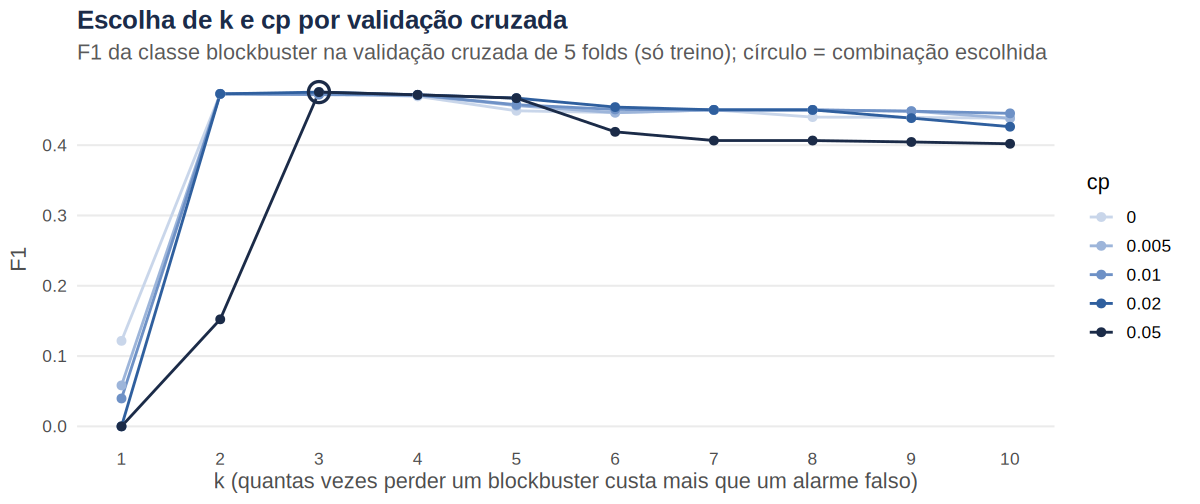

In [ ]:
options(repr.plot.height = 4.2)
ggplot(cv, aes(x = k, y = F1, color = factor(cp), group = factor(cp))) +
  geom_line(linewidth = 0.8) +
  geom_point(size = 2) +
  geom_point(data = melhor, aes(x = k, y = F1), inherit.aes = FALSE,
             color = TINTA, size = 5, shape = 21, stroke = 1.4) +
  scale_color_manual(values = c("#C9D6EA", "#9DB5DA", "#6E91C6", AZUL, TINTA), name = "cp") +
  scale_x_continuous(breaks = 1:10) +
  labs(title = "Escolha de k e cp por validação cruzada",
       subtitle = "F1 da classe blockbuster na validação cruzada de 5 folds (só treino); círculo = combinação escolhida",
       x = "k (quantas vezes perder um blockbuster custa mais que um alarme falso)", y = "F1") +
  theme(legend.position = "right")
options(repr.plot.height = 4.5)

**Observações**

- **k = 1** (erros com o mesmo peso) quase não aponta blockbusters: F1 entre 0 e 0,12.
- **De k = 2 a k = 4** há um **platô** com F1 ≈ 0,47 em praticamente todos os valores de `cp`. Ou seja, o resultado **não depende de um ajuste fino**: qualquer peso entre 2 e 4 leva a uma árvore parecida.
- **A partir de k = 5** o F1 cai devagar. O limiar fica baixo demais, e a árvore passa a apontar filmes demais como blockbuster (muitos alarmes falsos).
- O melhor F1 (0,476) aparece em k = 3, empatado entre `cp` = 0,02 e `cp` = 0,05. Pela regra de desempate, ficamos com **`cp` = 0,05**, a árvore mais simples. Com **k = 3**, uma folha é classificada como blockbuster quando mais de **25%** dos filmes nela são blockbusters.

**Modelo final.** Com `k` e `cp` escolhidos, ajustamos a árvore no treino completo. A tabela de complexidade (`printcp`) mostra, para cada número de cortes, a perda relativa no treino (`rel error`), em relação à árvore sem nenhum corte.

In [ ]:
arvore <- ajusta(treino, k_otimo, cp_otimo)
printcp(arvore)
cat("\nFolhas da árvore final:", sum(arvore$frame$var == "<leaf>"), "\n")


Classification tree:
rpart(formula = blockbuster ~ ., data = dados, method = "class", 
    parms = list(loss = matrix(c(0, k, 1, 0), nrow = 2)), control = rpart.control(maxdepth = maxdepth, 
        minbucket = 30, cp = cp, xval = 0))

Variables actually used in tree construction:
[1] budget_mi genre    

Root node error: 1413/3500 = 0.40371

n= 3500 

       CP nsplit rel error
1 0.15287      0   1.00000
2 0.05000      2   0.69427

Folhas da árvore final: 3 


**Observações**

- A árvore final tem só **2 cortes e 3 folhas** (profundidade 2), bem dentro do critério do Projeto 1 (profundidade menor que 4).
- Os dois cortes reduzem a perda ponderada no treino em cerca de **31%** em relação a não usar nenhuma variável (`rel error` = 0,694).
- Só **orçamento** e **gênero** foram usados, como previsto no Projeto 1 e confirmado pelos testes da seção 3.

### 4.2.3 Experimentos de controle

Como planejado no Projeto 1, repetimos exatamente o mesmo procedimento (mesmos `k`, `cp`, profundidade e divisão treino/teste) acrescentando as variáveis que ficaram de fora do modelo principal:

- **Pré + pós-lançamento** (`rating`, `vote_count` e `popularity`): quanto os sinais do público acrescentariam, se fossem conhecidos antes da estreia?
- **Pré + vazamento** (`revenue_usd`, `profit_usd` e `roi`): o que acontece quando o modelo "vê a resposta"?

In [ ]:
dados_ctrl <- cbind(dados_mod, df[, c(vars_vazamento, vars_pos)])
cenarios <- list(
  "Principal (pré-lançamento)" = vars_mod,
  "Pré + pós-lançamento"       = c(vars_mod, vars_pos),
  "Pré + vazamento"            = c(vars_mod, vars_vazamento)
)

controle <- do.call(rbind, lapply(names(cenarios), function(nm) {
  arv  <- ajusta(dados_ctrl[idx_treino, c(cenarios[[nm]], "blockbuster")], k_otimo, cp_otimo)
  prev <- predict(arv, dados_ctrl[-idx_treino, ], type = "class")
  data.frame(cenario = nm, t(round(metricas(dados_ctrl$blockbuster[-idx_treino], prev), 3)),
             variaveis_usadas = paste(setdiff(unique(as.character(arv$frame$var)), "<leaf>"), collapse = ", "),
             row.names = NULL)
}))
controle

cenario,acuracia,precisao,recall,F1,especificidade,variaveis_usadas
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Principal (pré-lançamento),0.769,0.343,0.777,0.476,0.768,"budget_mi, genre"
Pré + pós-lançamento,0.769,0.343,0.777,0.476,0.768,"budget_mi, genre"
Pré + vazamento,0.995,0.971,0.995,0.983,0.995,"profit_usd, roi"


**Observações**

- **Pré + pós-lançamento:** resultado **idêntico** ao do modelo principal. A árvore nem chegou a usar nota, votos ou popularidade. Isso confirma o T5 (seção 3): no dataset, os sinais do público não têm relação com a bilheteria.
- **Pré + vazamento:** o F1 salta para **0,983**, e a árvore passa a usar só `profit_usd` e `roi`, deixando orçamento e gênero de lado. Ela apenas **reconstrói a definição do alvo** (receita > 3× o orçamento equivale a ROI > 2). É um desempenho quase perfeito e totalmente inútil na prática, porque essas variáveis só existem depois da estreia. Isso mostra por que elas ficaram fora do modelo principal.

# 5. Resultados e Interpretação

## 5.1 Apresentação dos Resultados

### 5.1.1 A árvore final

Cada caixa mostra a classe prevista, a **taxa de blockbusters** naquele grupo e a **porcentagem dos filmes** do treino que caem nele. Caixas mais escuras têm taxa de blockbuster maior.

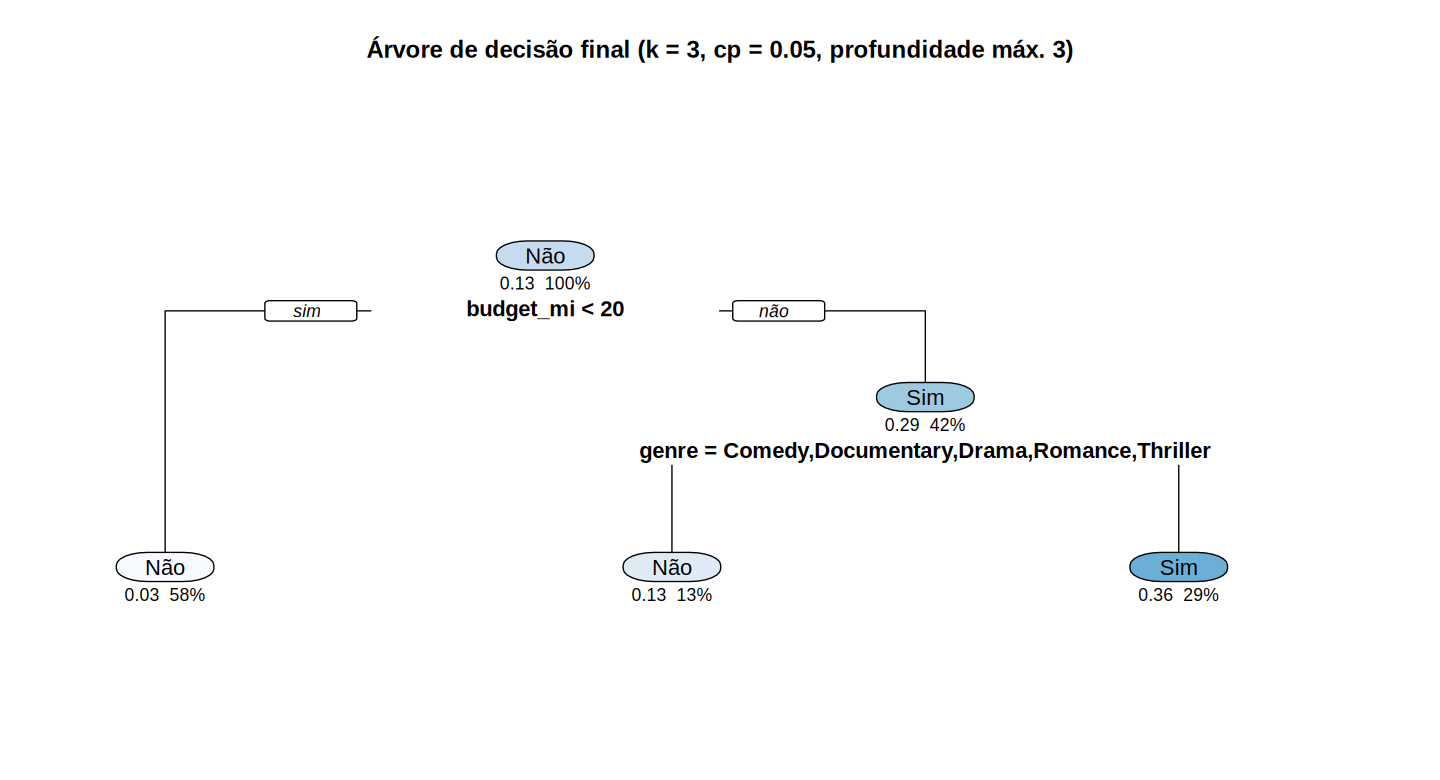

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 6.5)
rpart.plot(arvore, type = 2, extra = 106, under = TRUE, roundint = FALSE,
           box.palette = "Blues", shadow.col = NA, branch.lty = 1, tweak = 1.1,
           yes.text = "sim", no.text = "não",
           main = paste0("Árvore de decisão final (k = ", k_otimo, ", cp = ", cp_otimo, ", profundidade máx. 3)"))
options(repr.plot.width = 10, repr.plot.height = 4.5)

As mesmas regras em formato de tabela: cada linha é uma folha, com a taxa de blockbusters no treino (`blockbuster`) e a parcela dos filmes que ela cobre (`cover`).

In [ ]:
rpart.rules(arvore, roundint = FALSE, cover = TRUE)

imp <- arvore$variable.importance
if (!is.null(imp)) {
  data.frame(variavel = names(imp), importancia_pct = round(100 * imp / sum(imp), 1), row.names = NULL)
}

,blockbuster,,,,,,,,,cover
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2,0.03,when,budget_mi,<,20,,,,,58%
6,0.13,when,budget_mi,>=,20,&,genre,is,Comedy or Documentary or Drama or Romance or Thriller,13%
7,0.36,when,budget_mi,>=,20,&,genre,is,Action or Adventure or Animation or Horror or Sci-Fi,29%


variavel,importancia_pct
<chr>,<dbl>
budget_mi,59.7
genre,31.4
runtime_min,9.0


**Observações**

A árvore se resume a três regras:

| Regra | Filmes cobertos | Taxa de blockbuster | Previsão |
|---|---|---|---|
| Orçamento < US\$ 20 mi | 58% | 3% | Não |
| Orçamento ≥ US\$ 20 mi **e** gênero Comedy, Documentary, Drama, Romance ou Thriller | 13% | 13% | Não |
| Orçamento ≥ US\$ 20 mi **e** gênero Action, Adventure, Animation, **Horror** ou Sci-Fi | 29% | 36% | **Sim** |

- **O orçamento é a primeira pergunta**, como esperado desde o Projeto 1. O corte em US\$ 20 mi fica entre os pontos de virada vistos na EDA (US\$ 15 mi e US\$ 33,3 mi, seção 2.3.1).
- **Horror entra no grupo dos gêneros fortes.** Na visão isolada, Horror estava na média (12,4%), mas a EDA (2.3.7) mostrou que, com orçamento maior, sua taxa dispara. A árvore captou essa **interação** sozinha, algo que os testes da seção 3 (uma variável por vez) não conseguiam ver.
- **Importância das variáveis:** orçamento (59,7%) e gênero (31,4%) dominam. A duração (9,0%) aparece só como **corte substituto** (*surrogate*): ela não é usada em nenhum corte da árvore, mas "imita" parcialmente o gênero, o mesmo efeito de confusão do T4b. A década não aparece, coerente com o T3.

### 5.1.2 Desempenho no conjunto de teste

Comparamos a árvore com duas referências:

- **Baseline (Projeto 1):** sempre prevê "Não", que é a classe majoritária.
- **Regra de um corte só no orçamento:** uma árvore de profundidade 1 com só `budget_mi` e o mesmo `k`. Ela responde se o **gênero** e as demais variáveis acrescentam algo além do orçamento.

In [ ]:
prob_teste <- predict(arvore, teste, type = "prob")[, "Sim"]
prev_teste <- predict(arvore, teste, type = "class")

regra <- ajusta(treino[, c("budget_mi", "blockbuster")], k_otimo, cp = 0, maxdepth = 1)
prev_regra <- predict(regra, teste, type = "class")
prev_base  <- factor(rep("Não", nrow(teste)), levels = c("Não", "Sim"))

cat("Corte da regra de orçamento:\n"); print(rpart.rules(regra, roundint = FALSE))

cat("\nMatriz de confusão da árvore (teste):\n")
table(Real = teste$blockbuster, Previsto = prev_teste)

resultados <- data.frame(
  modelo = c("Baseline (sempre 'Não')", "Regra: só orçamento", "Árvore final"),
  rbind(metricas(teste$blockbuster, prev_base),
        metricas(teste$blockbuster, prev_regra),
        metricas(teste$blockbuster, prev_teste)),
  row.names = NULL
)
resultados %>% mutate(across(-modelo, ~ round(.x, 3)))
cat("AUC da árvore no teste:", br(auc(teste$blockbuster, prob_teste), 3), "\n")

Corte da regra de orçamento:
 blockbuster                     
        0.03 when budget_mi <  20
        0.29 when budget_mi >= 20

Matriz de confusão da árvore (teste):


     Previsto
Real  Não Sim
  Não 997 301
  Sim  45 157

modelo,acuracia,precisao,recall,F1,especificidade
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Baseline (sempre 'Não'),0.865,0.000,0.000,0.000,1.000
Regra: só orçamento,0.673,0.278,0.896,0.424,0.638
Árvore final,0.769,0.343,0.777,0.476,0.768


AUC da árvore no teste: 0,804 


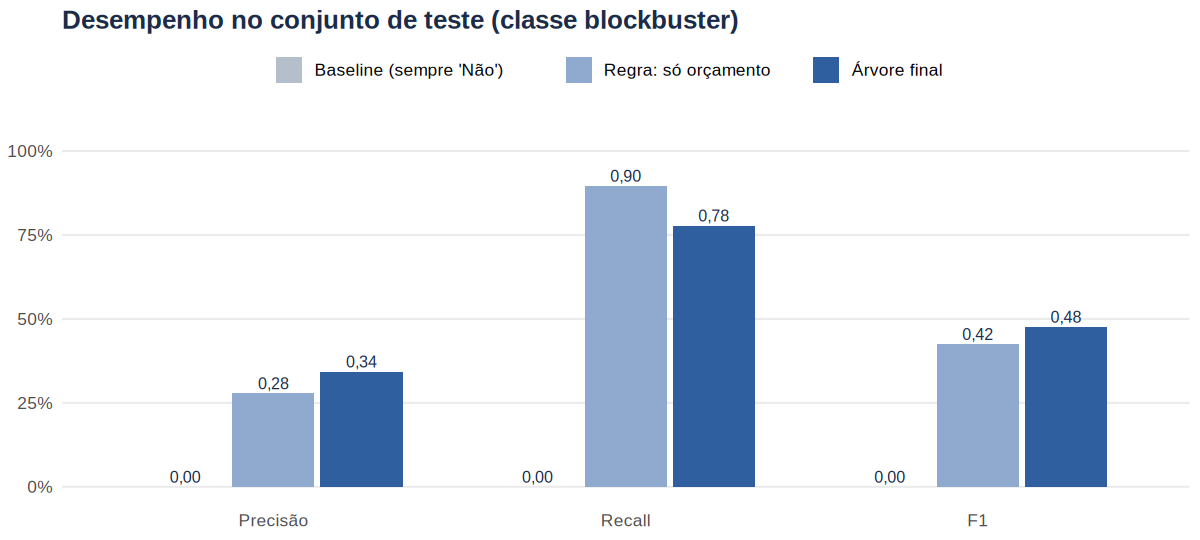

In [ ]:
resultados %>%
  select(modelo, precisao, recall, F1) %>%
  pivot_longer(-modelo, names_to = "metrica", values_to = "valor") %>%
  mutate(metrica = factor(metrica, levels = c("precisao", "recall", "F1"),
                          labels = c("Precisão", "Recall", "F1")),
         modelo  = factor(modelo, levels = resultados$modelo)) %>%
  ggplot(aes(x = metrica, y = valor, fill = modelo)) +
  geom_col(position = position_dodge(width = 0.75), width = 0.7) +
  geom_text(aes(label = br(valor, 2)), position = position_dodge(width = 0.75),
            vjust = -0.35, size = 3.4, color = TINTA) +
  scale_fill_manual(values = c(CINZA, "#8FA9CF", AZUL), name = NULL) +
  scale_y_continuous(limits = c(0, 1.05), labels = function(x) paste0(100 * x, "%")) +
  labs(title = "Desempenho no conjunto de teste (classe blockbuster)",
       x = NULL, y = NULL) +
  theme(legend.position = "top")

**Observações**

- **Matriz de confusão (teste, 1.500 filmes, 202 blockbusters):** a árvore encontrou **157 dos 202** blockbusters (recall de **77,7%**) e deixou passar 45. Dos 458 filmes que ela apontou, 157 são blockbusters de fato (precisão de **34,3%**).
- **A precisão parece baixa, mas é 2,5 vezes a taxa base.** Escolhendo um filme ao acaso, a chance de ser blockbuster é 13,5%; entre os filmes apontados pela árvore, é 34,3%.
- **A acurácia da árvore (76,9%) é menor que a do *baseline* (86,5%), e isso é esperado.** O *baseline* acerta 86,5% porque responde "Não" para todos e nunca encontra um blockbuster. A árvore troca parte desses acertos fáceis por encontrar quase 4 em cada 5 blockbusters. É por isso que a métrica do projeto é o F1, e não a acurácia.
- **Árvore × regra só de orçamento:** a regra encontra mais blockbusters (recall de 89,6%), mas à custa de muito mais alarmes falsos (precisão de 27,8%). Ao acrescentar o gênero, a árvore ganha precisão e chega a um F1 maior (**0,476 contra 0,424**).
- **Sem sobreajuste:** o F1 no teste (0,476) é igual ao da validação cruzada no treino (0,476).
- **AUC = 0,804:** sorteando um blockbuster e um não blockbuster, em 80% das vezes a árvore dá probabilidade maior ao blockbuster. Como referência, o estudo de Afonso et al. (2012), que inspirou o projeto, obteve 0,76 com uma árvore de duas variáveis, embora em outro domínio.

### 5.1.3 Teste da hipótese do Projeto 1

- **H0:** a árvore não supera o *baseline* em F1 ($F1_{árvore} \le F1_{baseline}$).
- **H1:** a árvore supera o *baseline* em F1 ($F1_{árvore} > F1_{baseline}$).

O F1 não tem uma distribuição conhecida, então usamos o **bootstrap**: sorteamos 2.000 vezes, com reposição, um novo conjunto de teste do mesmo tamanho e recalculamos o F1 de cada modelo nessas mesmas amostras. O **p-valor** unilateral é a proporção de reamostragens em que a árvore **não** supera a referência. O intervalo de 95% vem dos percentis 2,5% e 97,5% da diferença. Fazemos a mesma comparação com a regra de um corte só no orçamento.

In [ ]:
set.seed(2026)
B <- 2000
boot <- replicate(B, {
  i <- sample(nrow(teste), replace = TRUE)
  c(arvore = unname(metricas(teste$blockbuster[i], prev_teste[i])["F1"]),
    regra  = unname(metricas(teste$blockbuster[i], prev_regra[i])["F1"]),
    base   = unname(metricas(teste$blockbuster[i], prev_base[i])["F1"]))
})

compara <- function(dif, nome) {
  p <- mean(dif <= 0)
  data.frame(comparacao = nome,
             diferenca_F1 = br(mean(dif), 3),
             IC95 = paste0("[", br(quantile(dif, 0.025), 3), "; ", br(quantile(dif, 0.975), 3), "]"),
             p_valor = if (p == 0) paste0("< ", br(1 / B, 4)) else br(p, 4),
             decisao = decisao(p))
}
rbind(compara(boot["arvore", ] - boot["base", ],  "Árvore − baseline"),
      compara(boot["arvore", ] - boot["regra", ], "Árvore − regra só de orçamento"))

comparacao,diferenca_F1,IC95,p_valor,decisao
<chr>,<chr>,<chr>,<chr>,<chr>
Árvore − baseline,"0,474","[0,425; 0,523]","< 0,0005",Rejeita H0
Árvore − regra só de orçamento,"0,051","[0,025; 0,075]","< 0,0005",Rejeita H0


**Observações**

- **Árvore × *baseline*:** diferença de F1 de **0,474** (IC 95%: 0,425 a 0,523), e em nenhuma das 2.000 reamostragens a árvore ficou abaixo do *baseline* (p < 0,0005). **Rejeitamos H0: a hipótese do Projeto 1 se confirma.**
- **Árvore × regra só de orçamento:** a árvore também é melhor, com ganho de F1 de **0,051** (IC 95%: 0,025 a 0,075; p < 0,0005). Essa é a comparação mais exigente: o *baseline* tem F1 = 0 por definição, enquanto a regra de orçamento já é um concorrente razoável. O resultado mostra que **o gênero acrescenta informação além do orçamento**, coerente com o T2 e com a análise multivariada da EDA.
- **Ressalva:** o bootstrap mede a incerteza que vem de qual conjunto de teste foi sorteado, com a árvore fixa. Ele não mede quanto a própria árvore mudaria se fosse treinada com outra amostra.

## 5.2 Análise Crítica dos Resultados

Esta seção traduz a saída técnica da árvore para a linguagem de quem decide em um estúdio e discute até onde os resultados podem ser levados.

### O que cada regra diz ao estúdio

| Perfil do filme | Filmes cobertos | Taxa de blockbuster | Previsão | Leitura para o estúdio |
|---|---|---|---|---|
| Orçamento < US\$ 20 mi | 58% | 3% | Não | Não planejar bilheteria de blockbuster |
| Orçamento ≥ US\$ 20 mi em Comedy, Documentary, Drama, Romance ou Thriller | 13% | 13% | Não | Orçamento alto não compra sucesso nesses gêneros |
| Orçamento ≥ US\$ 20 mi em Action, Adventure, Animation, Horror ou Sci-Fi | 29% | 36% | **Sim** | Projeto que merece atenção prioritária |

- **Regra 1: orçamento abaixo de US\$ 20 mi.** O corte em US\$ 20 mi sugere que, abaixo desse valor, virar blockbuster é quase impossível, qualquer que seja o gênero: a taxa é de **3%**, contra **13,5%** na base inteira. A EDA já mostrava o mesmo padrão: **95,1%** dos blockbusters custam US\$ 15 mi ou mais. A conclusão para o estúdio **não** é que filmes baratos sejam maus negócios. Horror, por exemplo, tem a maioria dos filmes abaixo de US\$ 15 mi e o **maior ROI mediano da base (1,89)**. A conclusão é que um projeto pequeno não deve ser aprovado *contando* com um resultado de blockbuster; ele deve ser avaliado pelo retorno sobre o investimento.
- **Regra 2: orçamento ≥ US\$ 20 mi em gênero de baixa incidência.** A taxa de **13%** é praticamente a média da base. Isso sugere que, em Comedy, Documentary, Drama, Romance e Thriller, gastar mais tira o filme da zona quase impossível, mas não lhe dá nenhuma vantagem sobre um filme qualquer. Para o estúdio, um orçamento alto nesses gêneros precisa de uma justificativa que não seja a expectativa de bilheteria de blockbuster, porque o modelo não vê nesse perfil nenhum sinal dela.
- **Regra 3: orçamento ≥ US\$ 20 mi em gênero forte.** É o único perfil que a árvore aponta como blockbuster: **36%** dos filmes nele são blockbusters, bem acima da média de 13,5%. Mesmo assim, a maioria dos filmes desse grupo **não** vira blockbuster. Para o estúdio, entrar nesse perfil é motivo para **olhar o projeto com mais cuidado e priorizá-lo**, não uma garantia de sucesso.

### O que significam k = 3 e o limiar de 25%

- **Por que foi necessário.** Com as configurações padrão, a árvore ficou só com a raiz e respondeu "Não" para todos os filmes (F1 = **0**, igual ao *baseline*, seção 4.2.1). O motivo é que nenhum grupo grande de filmes passa de 50% de blockbusters (o máximo é Animation com orçamento ≥ US\$ 50 mi, com **44,1%**), então a classe majoritária de toda folha é "Não".
- **O que k = 3 quer dizer.** Na matriz de perdas, **perder um blockbuster custa 3 vezes mais que um alarme falso**. Com isso, uma folha passa a ser "Sim" quando mais de **25%** dos filmes nela são blockbusters, e não mais de 50%. Em termos de negócio: recusar ou subfinanciar um projeto que viraria blockbuster (e perder a bilheteria) é tratado como um erro mais grave que dedicar atenção e verba a um projeto que acaba não decolando.
- **Como isso decide as previsões.** A folha de gêneros fortes (**36%**) passa do limiar de 25% e vira "Sim"; a de gêneros fracos (**13%**) e a de orçamento baixo (**3%**) ficam abaixo e continuam "Não".
- **A escolha é estável.** O F1 forma um platô (≈ **0,47**) para k entre 2 e 4 (seção 4.2.2), então o resultado não depende de um ajuste fino do valor 3. O ponto fraco é que k foi escolhido para maximizar o F1, e não a partir de custos reais (ver 6.2 e 6.3).

### Como ler as métricas

- **Precisão de 34,3%.** Dos **458** filmes que a árvore apontou, **157** eram blockbusters. Isoladamente parece pouco, mas é **2,5 vezes** a taxa base (13,5%): o filtro concentra os blockbusters num grupo menor do catálogo. Ainda assim, cada alerta é mais provável de ser falso do que verdadeiro.
- **Recall de 77,7%.** A árvore encontrou **157 dos 202** blockbusters do teste, ou seja, **cerca de 4 em cada 5**. Os 45 que escaparam estão, por construção, nas duas folhas classificadas como "Não": são blockbusters de orçamento baixo ou de gêneros de baixa incidência, perfis em que o sucesso é raro e o modelo não tem como apostar.
- **Acurácia menor que a do *baseline* (76,9% contra 86,5%) não é um problema.** O *baseline* acerta 86,5% só porque 86,5% dos filmes não são blockbusters; ele nunca encontra um blockbuster sequer. A árvore troca parte desses acertos fáceis por encontrar a classe que interessa. Para um estúdio, um modelo que nunca aponta um sucesso não serve para nada, por mais alta que seja sua acurácia.
- **AUC de 0,804** e **F1 de 0,476 tanto na validação cruzada quanto no teste**: a árvore ordena bem os filmes por chance de sucesso e não está sobreajustada.

### Horror: uma interação que só a árvore captou

Isoladamente, Horror parece um gênero mediano: taxa de **12,4%**, próxima da média, e resíduo de apenas **−0,7** no qui-quadrado do T2. Mas **77,6%** dos filmes de terror custam menos de US\$ 15 mi, onde o piso de US\$ 100 mi de receita bloqueia quase todos. Quando o orçamento é maior, a taxa de Horror sobe para **40,4%** (US\$ 15–50 mi) e **55,6%** (US\$ 50 mi+). A árvore colocou Horror no grupo dos gêneros fortes **dentro do ramo de orçamento ≥ US\$ 20 mi**, uma interação *gênero × orçamento* que os testes da seção 3, que olham uma variável por vez, não detectavam.

Para o estúdio, isso sugere que Horror é o gênero que mais rende por dólar quando é barato **e** um dos mais promissores quando recebe orçamento maior. A evidência no topo, porém, é frágil: só **18** filmes de Horror custam US\$ 50 mi ou mais, e por isso a árvore (com `minbucket` = 30) não criou uma folha só para eles.

### Ponto crítico: quanto do poder do orçamento é mecânico?

Parte do poder do orçamento **vem da própria definição do alvo**. Um filme só é blockbuster se faturar mais de US\$ 100 mi; para um filme barato, isso exige multiplicar o orçamento muito mais que 3 vezes. Abaixo de **US\$ 33,3 mi** (onde 3 × orçamento = US\$ 100 mi), quem limita o alvo é o piso de receita, não o desempenho relativo do filme. A seção 2.3.1 mostra isso com clareza:

| Faixa de orçamento | Filmes que triplicaram o orçamento | Taxa de blockbuster |
|---|---|---|
| < US\$ 5 mi | 17,7% | 0,08% |
| US\$ 5–15 mi | 23,2% | 2,54% |
| US\$ 15–30 mi | 26,6% | 14,22% |
| US\$ 30–50 mi | 29,7% | 28,78% |
| US\$ 50–100 mi | 30,9% | 30,86% |
| US\$ 100–200 mi | 33,4% | 33,44% |
| US\$ 200 mi+ | 39,8% | 39,78% |

Filmes baratos triplicam o orçamento em proporção não muito menor que os caros, mas quase nunca chegam a US\$ 100 mi: **591** filmes superaram 3× o orçamento sem alcançar o piso. Ou seja, o corte em US\$ 20 mi reproduz em boa parte o piso da definição. Ele diz que "filmes pequenos raramente faturam US\$ 100 mi", o que é quase uma consequência de escala, e não uma descoberta sobre o que faz um filme dar certo.

**Quanto isso pesa?** Bastante. O orçamento responde por **59,7%** da importância, e a regra que usa só o orçamento já atinge F1 de **0,424**, contra **0,476** da árvore. Ou seja, a maior parte do ganho sobre o *baseline* vem desse componente em boa parte mecânico. Acima de US\$ 33,3 mi, onde só a condição de 3× importa, o efeito do orçamento é bem mais fraco: a taxa vai de **28,8%** (US\$ 30–50 mi) a **39,8%** (US\$ 200 mi+). Já o gênero, na faixa de US\$ 50 mi+, separa taxas de **10,4%** (Drama) a **44,1%** (Animation). A parte que **não** é mecânica, o ganho trazido pelo gênero (F1 **+0,051**, IC 95%: 0,025 a 0,075), é menor, mas é real, e é ela que diz algo ao estúdio sobre o *tipo* de projeto.

Conclusão: o modelo responde bem à pergunta "este filme pode virar blockbuster, na definição usada?", mas **não** deve ser lido como "orçamento maior causa sucesso". Um estúdio interessado em rentabilidade deveria olhar também o ROI (ver 6.3).

### O que os experimentos de controle mostram

- **Pré + pós-lançamento:** resultado **idêntico** (F1 = 0,476), e a árvore nem usou nota, votos ou popularidade. Neste dataset, os sinais do público não têm relação com a bilheteria (T5). Isso é muito provavelmente um **artefato da geração sintética**, e não uma conclusão sobre a indústria real, onde esses sinais costumam acompanhar a receita.
- **Pré + vazamento:** F1 de **0,983**, usando só `profit_usd` e `roi`. A árvore apenas **reconstrói a definição do alvo** (receita > 3× orçamento equivale a ROI > 2). A lição é que um F1 quase perfeito é um **sinal de alerta**, não de sucesso: essas variáveis só existem depois da estreia. O número honesto para uma decisão pré-lançamento é **0,476**.

### Conexão com o Projeto 1

| Expectativa do Projeto 1 | Resultado | Situação |
|---|---|---|
| Orçamento e gênero nas primeiras divisões | Orçamento na 1ª divisão, gênero na 2ª; são as **únicas** variáveis usadas | Confirmada |
| Árvore legível, com profundidade < 4 | Profundidade **2**, com **3 folhas** | Confirmada |
| H1: a árvore supera o *baseline* em F1 | F1 de **0,476** contra 0; diferença de **0,474** (IC 95%: 0,425 a 0,523), p < 0,0005 | **H0 rejeitada** |
| Referência de Afonso et al. (2012): AUROC de 0,76 com uma árvore de duas variáveis | AUC de **0,804**, também com uma árvore de duas variáveis | Comparável |

A comparação com Afonso et al. é só indicativa: o domínio é outro (risco de influenza), e lá os dados eram reais, enquanto aqui são sintéticos. O paralelo que se sustenta é metodológico: em ambos os casos, uma árvore CART enxuta, com duas variáveis, chega a uma capacidade de discriminação razoável e a regras fáceis de explicar.

# 6. Conclusão

## 6.1 Resumo dos Insights

**Resposta à pergunta da seção 1.2:** sim. Usando apenas atributos conhecidos antes do lançamento, uma árvore de decisão com **duas perguntas** (orçamento e gênero) distingue os blockbusters dos demais muito melhor que o *baseline*. No conjunto de teste, ela encontra **77,7%** dos blockbusters, com precisão de **34,3%** (2,5 vezes a taxa base), **F1 de 0,476** contra **0** do *baseline* e **AUC de 0,804**. A distinção serve como **triagem**, mas não é precisa a ponto de decidir sozinha: cerca de 2 em cada 3 filmes apontados não viram blockbuster.

**Principais descobertas**

- **O orçamento é o fator dominante, mas parte do seu poder é mecânica.** Blockbusters têm orçamento mediano **4,4 vezes** maior (US\$ 52,4 mi contra US\$ 11,8 mi; P(sup.) = **0,822** no T1), e o corte em US\$ 20 mi separa **58%** dos filmes com só **3%** de blockbusters. Boa parte disso, porém, reflete o piso de US\$ 100 mi de receita da própria definição do alvo (5.2).
- **O gênero acrescenta informação real além do orçamento.** Animation, Action, Adventure e Sci-Fi são **40,1%** do catálogo e concentram **78,0%** dos blockbusters (V de Cramér = **0,323** no T2). Na árvore, o gênero melhora o F1 da regra só de orçamento em **0,051** (IC 95%: 0,025 a 0,075).
- **Gênero e orçamento interagem, e o caso mais claro é Horror.** Sozinho, Horror fica na média (**12,4%**), mas com orçamento de US\$ 15–50 mi sua taxa sobe para **40,4%**. A árvore o colocou no grupo dos gêneros fortes, uma interação que os testes de uma variável por vez não viam.
- **Década e duração não ajudam.** A taxa de blockbuster não muda entre décadas (p = **0,532**), nem o orçamento (p = **0,824**, sem inflação). A duração parece importar na visão marginal, mas o efeito some quando o gênero é controlado (LRT p = **0,476** e **0,770**). A árvore não usou nenhuma das duas; a duração aparece só como corte substituto (**9,0%** da importância).
- **Sinais do público não ajudam, e o vazamento engana.** Acrescentar nota, votos e popularidade deixou o resultado idêntico, provavelmente por um artefato do dataset sintético. Acrescentar lucro e ROI leva o F1 a **0,983**, mas só porque a árvore reconstrói a definição do alvo.
- **A hipótese do Projeto 1 foi confirmada.** A árvore supera o *baseline* em F1 (diferença de **0,474**, IC 95%: 0,425 a 0,523, p < 0,0005), tem profundidade **2** (< 4) e usa orçamento e gênero nas primeiras divisões, como previsto. O F1 é o mesmo na validação cruzada e no teste (**0,476**), sem sinal de sobreajuste.

## 6.2 Recomendações Práticas

**1. Usar a árvore como filtro de triagem na aprovação de projetos.**

- **Ação:** todo projeto com orçamento previsto de **US\$ 20 mi ou mais** em **Action, Adventure, Animation, Horror ou Sci-Fi** entra em uma fila de **análise aprofundada** (estudo de mercado, teste de roteiro, plano de lançamento amplo) e tem prioridade na verba de marketing e distribuição. Os demais projetos seguem o fluxo normal e são avaliados pelo retorno sobre o investimento, sem expectativa de bilheteria de blockbuster.
- **Justificativa:** esse perfil reúne **29%** dos filmes, mas tem **36%** de blockbusters. No teste, os filmes apontados continham **157 dos 202** blockbusters (recall de **77,7%**), com chance de sucesso **2,5 vezes** a da base. Como a precisão é de **34,3%**, o alerta deve **abrir** uma análise, nunca aprovar um projeto sozinho. Do outro lado, projetos abaixo de US\$ 20 mi têm só **3%** de blockbusters, e projetos caros em gêneros fracos ficam em **13%**, na média da base: nesses casos, o orçamento alto precisa de outra justificativa.

**2. Ajustar o peso `k` aos custos reais do estúdio antes de usar o modelo.**

- **Ação:** estimar, com a área financeira, quanto custa **deixar passar um blockbuster** (bilheteria perdida por recusar ou subfinanciar o projeto) e quanto custa **um alarme falso** (a análise aprofundada e a verba extra gastas em um filme que não decola). A razão entre os dois é o `k`, e o limiar de decisão passa a ser 1 / (1 + `k`). Com esse valor, a árvore deve ser reajustada e revalidada pelo mesmo procedimento da seção 4.2.
- **Justificativa:** o `k` = 3 atual foi escolhido para maximizar o F1, um critério técnico, e não pelo custo real dos erros. A seção 4 mostra que essa escolha muda o comportamento do modelo: com `k` = 1, a árvore quase não aponta blockbusters (F1 entre **0** e **0,12**); uma regra mais agressiva, como o corte só no orçamento, encontra **89,6%** dos blockbusters, mas com precisão de só **27,8%**. A boa notícia é o platô de F1 ≈ **0,47** para `k` entre 2 e 4: se os custos reais estiverem nessa faixa, a árvore atual continua adequada. Mantida a árvore atual, as previsões só mudam se o novo limiar cruzar a taxa de alguma folha (**13%** ou **36%**).

## 6.3 Limitações e Próximos Passos

**Limitações**

- **Dados sintéticos.** O dataset foi gerado por simulação, e isso aparece em vários pontos: o orçamento máximo de **US\$ 2,37 bi** está muito acima de qualquer orçamento real, não há inflação entre 1980 e 2024, e as durações parecem cortadas em 60 minutos. A **ausência de efeito das variáveis pós-lançamento** (correlação com o alvo e com as variáveis financeiras de |ρ| ≤ 0,035) é provavelmente um artefato da geração, e não um fato da indústria. As conclusões valem para o **método**, não para o mercado real.
- **Poucas preditoras pré-lançamento.** O modelo só tinha quatro variáveis (e usou duas). Faltam informações que um estúdio de fato tem antes da estreia: **elenco, diretor, se o filme é de franquia ou sequência, verba de marketing e data de estreia** (feriados, concorrência).
- **Precisão moderada.** Dos **458** filmes apontados no teste, **301** não eram blockbusters: cerca de **2 em cada 3 alertas são falsos**. A árvore serve para triagem, não para decisão final.
- **Um único split 70/30 e a ressalva do bootstrap.** Todos os números de teste vêm de uma única divisão treino/teste. O bootstrap da seção 5.1.3 mede a incerteza de qual conjunto de teste foi sorteado, **com a árvore fixa**; ele não mede quanto a árvore mudaria se fosse treinada com outra amostra.
- **Instabilidade das árvores.** Pequenas mudanças nos dados podem deslocar o corte de orçamento (hoje em US\$ 20 mi) ou reagrupar os gêneros. Horror, por exemplo, entra no grupo forte com base em poucos filmes caros (só **18** acima de US\$ 50 mi).
- **`k` escolhido por F1, não por custo real.** O limiar de 25% reflete um critério estatístico, não o custo de negócio de cada tipo de erro (ver 6.2).
- **Definição de blockbuster arbitrária.** Os limites de 3× o orçamento e de US\$ 100 mi são convenções do dataset. O piso de US\$ 100 mi explica parte do poder do orçamento (5.2), e outra definição (por exemplo, só pelo ROI) poderia mudar bastante a árvore. Em dados reais, um piso nominal fixo também favoreceria os filmes mais recentes, por causa da inflação.

**Próximos passos**

1. **Repetir a análise com dados reais** de orçamento e bilheteria, acrescentando as preditoras que faltam (elenco, diretor, franquia, marketing, data de estreia).
2. **Comparar com *random forest* e *boosting*,** para medir quanto desempenho se perde ao escolher uma árvore única e legível, e se os modelos de conjunto confirmam a importância de orçamento e gênero.
3. **Usar validação cruzada repetida** (ou vários splits treino/teste) para estimar a variabilidade das métricas e verificar com que frequência o corte em torno de US\$ 20 mi e o agrupamento dos gêneros se repetem.
4. **Calibrar o limiar pelo custo real** dos erros, como descrito na recomendação 2 da seção 6.2.
5. **Modelar também o ROI ou o lucro como alvo,** para separar o que é efeito real do orçamento e do gênero do que é efeito mecânico do piso de US\$ 100 mi.

# Referências

- AFONSO, A. M.; EBELL, M. H.; GONZALES, R.; STEIN, J.; GENTON, B.; SENN, N. The use of classification and regression trees to predict the likelihood of seasonal influenza. *Family Practice*, v. 29, p. 671–677, 2012. doi:10.1093/fampra/cms020.
- LEELAVATHI, V. R. *What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue*. Kaggle. Licença CC0.
- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009.
- QUINLAN, J. R. Induction of Decision Trees. *Machine Learning*, v. 1, p. 81–106, 1986.
- THERNEAU, T.; ATKINSON, B. *rpart: Recursive Partitioning and Regression Trees*. Pacote R.
- WICKHAM, H. *ggplot2: Elegant Graphics for Data Analysis*. Springer, 2016.